# Counterfactual Based Severity Quantification and Temporal Uncertainty for Railway Track Geometry

**Reproduction notebook.** Runs from the raw inspection file `RawD.xlsx` to every table, figure and reported number in the paper.

**Authors:** Benjamin Gyimah Boateng and Nii Attoh-Okine, University of Maryland

---

### What this notebook does

| Section | Content | Paper output |
|---|---|---|
| 0 | Setup, configuration, data location | |
| 1 | Load data, select features, label defects | Table 1, Table 2 |
| 2 | Exploratory analysis and drift | Fig. 1, Fig. 2, Table 3, Sec. 4 numbers |
| 3 | Baseline classifier | Table 8 |
| 4 | Counterfactual generation, 2014 reference cohort | Table 4, Fig. 3 |
| 5 | Severity validation against subsequent defect occurrence | Tables 5 to 7, Fig. 4 to 6 |
| 6 | Temporal transfer of reference perturbations | Table 9, Fig. 7 to 9, Sec. 5.5 to 5.8 numbers |
| 7 | Recalibration and new counterfactual generation | Tables 10 and 11, Fig. 10 |
| 8 | Sensitivity to the proximity weight | Appendix table |
| 9 | Check of every reported value against the paper | |

### How to run

1. Put `RawD.xlsx` at the top level of your Google Drive (or upload it when prompted).
2. `Runtime` then `Run all`.
3. All figures are written to `outputs/figures` and all tables to `outputs/tables`.

### Runtime

About 35 to 60 minutes on a standard Colab CPU. Counterfactual generation dominates. Results are cached in `outputs/cache`, so a second run takes about two minutes. Set `RUN_LAMBDA_SWEEP = False` in Section 0 to skip the appendix sensitivity analysis and halve the runtime.

### Reproducibility note

The classifier is fitted with **XGBoost 3.2.0**. The fitted trees differ slightly between XGBoost releases, which moves the reported values in the third decimal. The first code cell pins that version so the notebook reproduces the published numbers exactly.

## 0. Setup

### 0.1 Install the pinned XGBoost version
If Colab asks to restart the runtime after this cell, restart and run all cells again.

In [1]:
%pip install -q "xgboost==3.2.0" openpyxl

Note: you may need to restart the kernel to use updated packages.


### 0.2 Imports and plotting style

In [2]:
import os, re, time, pickle, warnings, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import scipy, sklearn, xgboost
from scipy.optimize import brentq, minimize
from scipy.stats import spearmanr, pearsonr, ks_2samp, beta
from sklearn.metrics import roc_auc_score, precision_recall_fscore_support
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from xgboost import XGBClassifier
from IPython.display import display

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)

print('xgboost', xgboost.__version__, '| scipy', scipy.__version__,
      '| scikit-learn', sklearn.__version__, '| numpy', np.__version__,
      '| pandas', pd.__version__)
if xgboost.__version__ != '3.2.0':
    print('WARNING: XGBoost is not 3.2.0. Values will differ slightly from the paper.')

def set_style():
    """Seaborn paper style used for most figures."""
    sns.set_theme(style='whitegrid', context='paper', font_scale=1.15)
    plt.rcParams.update({
        'figure.dpi': 110, 'savefig.dpi': 300, 'savefig.bbox': 'tight',
        'savefig.facecolor': 'white', 'figure.facecolor': 'white', 'axes.facecolor': 'white',
        'font.family': 'sans-serif',
        'font.sans-serif': ['DejaVu Sans', 'Liberation Sans', 'Arial', 'Helvetica'],
        'axes.titleweight': 'bold', 'axes.spines.top': False, 'axes.spines.right': False,
    })
set_style()

xgboost 3.2.0 | scipy 1.18.1 | scikit-learn 1.9.1 | numpy 2.5.3 | pandas 3.0.5


### 0.3 Configuration
All choices that affect the results are collected here.

In [3]:
SEED = 42                      # random seed used for the classifier and the search
LAMBDA = 0.5                   # proximity weight in the counterfactual objective (Eq. 1)
RUN_LAMBDA_SWEEP = True        # appendix sensitivity analysis (about half of the runtime)
LAMBDA_GRID = [0.05, 0.1, 0.25, 0.5, 1.0, 2.0, 5.0]
USE_CACHE = True               # reuse counterfactuals saved by an earlier run

FEATURES = ['GAGE', 'ALI_L_62', 'ALI_R_62', 'WARP_62', 'XLEVEL']
WARP = FEATURES.index('WARP_62')
XLEV = FEATURES.index('XLEVEL')

# Project limits define the defect label. FRA Class 7 limits bound the search.
PROJECT_LIMITS = {'GAGE': (56.3, 57.2), 'ALI_L_62': (-0.20, 0.20), 'ALI_R_62': (-0.20, 0.20),
                  'WARP_62': (-0.30, 0.30), 'XLEVEL': (-0.80, 0.80)}
FRA_LIMITS     = {'GAGE': (56.0, 57.5), 'ALI_L_62': (-0.50, 0.50), 'ALI_R_62': (-0.50, 0.50),
                  'WARP_62': (-1.00, 1.00), 'XLEVEL': (-1.00, 1.00)}

TIER_BINS   = [0, 0.03, 0.08, 0.15, np.inf]      # severity tiers on |dWARP| (in.)
TIER_NAMES  = ['Marginal', 'Moderate', 'Severe', 'Critical']
HORIZONS    = [1, 3, 6]                          # next 1, 3 and 6 available inspections

OUT_DIR   = 'outputs'
FIG_DIR   = os.path.join(OUT_DIR, 'figures')
TAB_DIR   = os.path.join(OUT_DIR, 'tables')
CACHE_DIR = os.path.join(OUT_DIR, 'cache')
for d in (FIG_DIR, TAB_DIR, CACHE_DIR):
    os.makedirs(d, exist_ok=True)

RESULTS = {}     # every reported value is stored here and checked in Section 9

def save_fig(fig, name):
    for ext in ('png', 'pdf'):
        fig.savefig(os.path.join(FIG_DIR, f'{name}.{ext}'), dpi=300, bbox_inches='tight')
    print(f'saved {FIG_DIR}/{name}.png and .pdf')

def save_table(table, name):
    table.to_csv(os.path.join(TAB_DIR, f'{name}.csv'))
    print(f'saved {TAB_DIR}/{name}.csv')

### 0.4 Locate the data file
The notebook looks for `RawD.xlsx` in Google Drive, then in the working folder, and finally asks for an upload.

In [4]:
def locate_data():
    candidates = ['RawD.xlsx', 'data/RawD.xlsx', '../data/RawD.xlsx']
    try:
        from google.colab import drive
        if not os.path.exists('/content/drive/MyDrive'):
            drive.mount('/content/drive')
        candidates = ['/content/drive/MyDrive/RawD.xlsx'] + candidates
    except ImportError:
        pass
    for p in candidates:
        if os.path.exists(p):
            return p
    try:
        from google.colab import files
        print('RawD.xlsx not found. Please upload it.')
        up = files.upload()
        return next(iter(up))
    except ImportError:
        raise FileNotFoundError('RawD.xlsx not found. Place it next to this notebook.')

DATA_PATH = locate_data()
print('Using data file:', DATA_PATH)

Using data file: RawD.xlsx


## 1. Data

### 1.1 Load the monthly inspection sheets
The workbook holds one sheet per inspection, named `month_year`. Each row is one 0.3 m (1 ft) measurement.

In [5]:
sheets = pd.read_excel(DATA_PATH, sheet_name=None, engine='openpyxl')
pattern = re.compile(r'^(\d{1,2})_(\d{4})$')

frames = []
for name, sheet in sheets.items():
    m = pattern.match(name)
    if not m:
        continue                      # skip non data sheets such as 'Chart'
    month, year = map(int, m.groups())
    sheet = sheet.copy()
    sheet['date']  = pd.Timestamp(year=year, month=month, day=1)
    sheet['year']  = year
    sheet['month'] = month
    frames.append(sheet)

raw = pd.concat(frames, ignore_index=True).sort_values('date').reset_index(drop=True)
for c in ('MILE', 'FEET'):
    raw[c] = pd.to_numeric(raw[c], errors='coerce').astype('Int64')

print(f'{len(frames)} inspections, {len(raw):,} rows, '
      f'{raw["date"].min():%b %Y} to {raw["date"].max():%b %Y}')

28 inspections, 147,566 rows, Jun 2013 to Apr 2016


### 1.2 Select features and label defects
Five geometry features are kept. A record is **defective** when at least one feature lies outside its project limit.

In [6]:
df = raw.replace(-9999, np.nan).dropna(subset=FEATURES).copy()
df['MILE'] = df['MILE'].astype(int)
df['FEET'] = df['FEET'].astype(int)

def outside(frame, feature, limits):
    lo, hi = limits[feature]
    return (frame[feature] < lo) | (frame[feature] > hi)

for f in FEATURES:
    df[f'viol_{f}'] = outside(df, f, PROJECT_LIMITS)
df['defect'] = df[[f'viol_{f}' for f in FEATURES]].any(axis=1).astype(int)

# Defect type used throughout: WARP driven (any WARP violation) or XLEVEL only
df['warp_driven'] = df['viol_WARP_62']
df['xlevel_only'] = df['viol_XLEVEL'] & ~df['viol_WARP_62']

n_locations = df[['MILE', 'FEET']].drop_duplicates().shape[0]
years_per_location = df.groupby(['MILE', 'FEET'])['year'].nunique()
RESULTS['n_records']   = len(df)
RESULTS['n_locations'] = n_locations
RESULTS['pct_locations_all_years'] = 100 * (years_per_location == 4).mean()
RESULTS['overall_defect_rate_pct'] = 100 * df['defect'].mean()

print(f'records              : {len(df):,}')
print(f'measurement locations: {n_locations:,}')
print(f'in all four years    : {RESULTS["pct_locations_all_years"]:.1f}%')
print(f'overall defect rate  : {RESULTS["overall_defect_rate_pct"]:.2f}%')
print(f'spacing between locations (ft): '
      f'{df[df["date"] == df["date"].min()].sort_values("FEET")["FEET"].diff().value_counts().to_dict()}')

records              : 147,550
measurement locations: 5,279
in all four years    : 99.8%
overall defect rate  : 3.55%
spacing between locations (ft): {1.0: 5268, 0.0: 1}


### 1.3 Table 1. Dataset overview by calendar year

In [7]:
table1 = df.groupby('year').agg(
    N=('defect', 'size'),
    Defects=('defect', 'sum'),
    Rate_pct=('defect', lambda x: 100 * x.mean()),
    WARP_sigma_in=('WARP_62', 'std'),
    WARP_tail=('WARP_62', lambda x: (x.abs() > 0.30).mean()),
)
display(table1.round({'Rate_pct': 2, 'WARP_sigma_in': 4, 'WARP_tail': 4}))
save_table(table1, 'table1_dataset_overview')
for y, r in table1.iterrows():
    RESULTS[f'N_{y}'] = int(r['N']); RESULTS[f'defects_{y}'] = int(r['Defects'])
    RESULTS[f'rate_{y}'] = r['Rate_pct']; RESULTS[f'warp_sigma_{y}'] = r['WARP_sigma_in']
    RESULTS[f'warp_tail_{y}'] = r['WARP_tail']

,N,Defects,Rate_pct,WARP_sigma_in,WARP_tail
year,,,,,
2013,31620,775,2.45,0.0983,0.0127
2014,42152,649,1.54,0.0959,0.0121
2015,52696,1692,3.21,0.1047,0.0235
2016,21082,2129,10.10,0.1406,0.0572


saved outputs/tables/table1_dataset_overview.csv


### 1.4 Table 2. Geometry features and limits

In [8]:
table2 = pd.DataFrame({
    'Physical basis': ['Rail spacing', 'Left 62 ft alignment', 'Right 62 ft alignment',
                       '62 ft chord warp', 'Crosslevel deviation'],
    'FRA limit (in.)':     [f'{FRA_LIMITS[f][0]} to {FRA_LIMITS[f][1]}' for f in FEATURES],
    'Project limit (in.)': [f'{PROJECT_LIMITS[f][0]} to {PROJECT_LIMITS[f][1]}' for f in FEATURES],
}, index=FEATURES)
display(table2)
save_table(table2, 'table2_limits')

,Physical basis,FRA limit (in.),Project limit (in.)
GAGE,Rail spacing,56.0 to 57.5,56.3 to 57.2
ALI_L_62,Left 62 ft alignment,-0.5 to 0.5,-0.2 to 0.2
ALI_R_62,Right 62 ft alignment,-0.5 to 0.5,-0.2 to 0.2
WARP_62,62 ft chord warp,-1.0 to 1.0,-0.3 to 0.3
XLEVEL,Crosslevel deviation,-1.0 to 1.0,-0.8 to 0.8


saved outputs/tables/table2_limits.csv


## 2. Exploratory analysis and drift

### 2.1 Variability and tail exceedance over time (Section 4.1)

In [9]:
monthly_sd = df.groupby('date')[FEATURES].std()
yearly_sd  = df.groupby('year')[FEATURES].std()

sd_ref  = monthly_sd[monthly_sd.index.year <= 2014]['WARP_62'].mean()
sd_2016 = monthly_sd[monthly_sd.index.year == 2016]['WARP_62'].mean()
tail_ref  = (df[df['year'] <= 2014]['WARP_62'].abs() > 0.30).mean()
tail_2016 = (df[df['year'] == 2016]['WARP_62'].abs() > 0.30).mean()

RESULTS['warp_sd_ref'] = sd_ref;   RESULTS['warp_sd_2016'] = sd_2016
RESULTS['warp_sd_increase_pct'] = 100 * (sd_2016 / sd_ref - 1)
RESULTS['gage_sd_2015'] = yearly_sd.loc[2015, 'GAGE']
RESULTS['tail_ref_pct'] = 100 * tail_ref; RESULTS['tail_2016_pct'] = 100 * tail_2016
RESULTS['tail_fold'] = tail_2016 / tail_ref

print(f'WARP monthly sigma, 2013 to 2014 mean : {sd_ref:.3f} in.')
print(f'WARP monthly sigma, 2016 mean         : {sd_2016:.3f} in.  (+{RESULTS["warp_sd_increase_pct"]:.0f}%)')
print(f'GAGE sigma in 2015                    : {RESULTS["gage_sd_2015"]:.3f} in.')
print(f'P(|WARP| > 0.30), 2013 to 2014        : {100*tail_ref:.1f}%')
print(f'P(|WARP| > 0.30), 2016                : {100*tail_2016:.1f}%  ({RESULTS["tail_fold"]:.1f} fold)')
display(yearly_sd.round(4))

WARP monthly sigma, 2013 to 2014 mean : 0.097 in.
WARP monthly sigma, 2016 mean         : 0.141 in.  (+45%)
GAGE sigma in 2015                    : 0.094 in.
P(|WARP| > 0.30), 2013 to 2014        : 1.2%
P(|WARP| > 0.30), 2016                : 5.7%  (4.6 fold)


,GAGE,ALI_L_62,ALI_R_62,WARP_62,XLEVEL
year,,,,,
2013,0.0492,0.0505,0.0579,0.0983,0.2276
2014,0.0471,0.0412,0.0428,0.0959,0.2156
2015,0.0939,0.0439,0.0495,0.1047,0.2549
2016,0.0552,0.0510,0.0546,0.1406,0.2556


### 2.2 Figure 1. Defect triggering features

saved outputs/figures/defect_triggers.png and .pdf


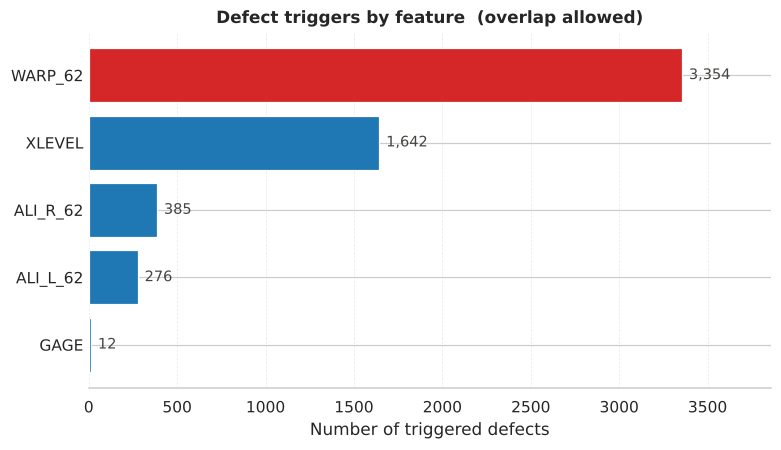

In [10]:
triggers = {f: int(df[f'viol_{f}'].sum()) for f in ['WARP_62', 'XLEVEL', 'ALI_R_62', 'ALI_L_62', 'GAGE']}
RESULTS.update({f'trigger_{k}': v for k, v in triggers.items()})

labels, vals = list(triggers), list(triggers.values())
fig, ax = plt.subplots(figsize=(8, 4.2))
colors = ['#d62728'] + ['#1f77b4'] * (len(labels) - 1)          # highlight WARP
ax.barh(labels[::-1], vals[::-1], color=colors[::-1], edgecolor='white')
for i, v in enumerate(vals[::-1]):
    ax.text(v + max(vals) * 0.012, i, f'{v:,}', va='center', fontsize=9.5, color='#444441')
ax.set_xlabel('Number of triggered defects')
ax.set_title('Defect triggers by feature  (overlap allowed)')
ax.set_xlim(0, max(vals) * 1.15)
ax.grid(axis='x', alpha=0.4, linewidth=0.5, linestyle='--')
sns.despine(ax=ax, left=True); ax.tick_params(axis='y', length=0)
save_fig(fig, 'defect_triggers'); plt.show()

### 2.3 Figure 2. Defect composition by year (Section 4.2)

,n,WARP driven,XLEVEL only,Other only,Any XLEVEL
year,,,,,
2013,775,51.6,16.4,32.0,16.4
2014,649,78.7,21.3,0.0,21.3
2015,1692,73.1,24.5,2.4,25.5
2016,2129,56.6,37.2,6.1,44.4


saved outputs/tables/defect_composition_by_year.csv


saved outputs/figures/defect_composition_by_year.png and .pdf


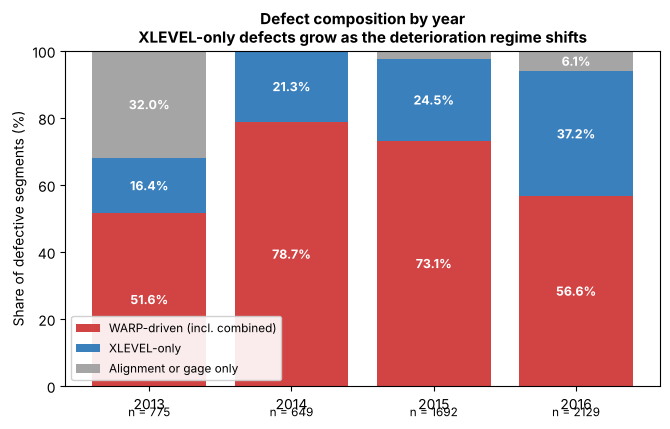

In [11]:
rows = []
for y in (2013, 2014, 2015, 2016):
    d = df[(df['year'] == y) & (df['defect'] == 1)]
    rows.append({'year': y, 'n': len(d),
                 'WARP driven':   100 * d['warp_driven'].mean(),
                 'XLEVEL only':   100 * d['xlevel_only'].mean(),
                 'Other only':    100 * (~d['viol_WARP_62'] & ~d['viol_XLEVEL']).mean(),
                 'Any XLEVEL':    100 * d['viol_XLEVEL'].mean()})
composition = pd.DataFrame(rows).set_index('year')
display(composition.round(1))
save_table(composition, 'defect_composition_by_year')
for y in composition.index:
    RESULTS[f'warp_driven_pct_{y}'] = composition.loc[y, 'WARP driven']
    RESULTS[f'xlevel_only_pct_{y}'] = composition.loc[y, 'XLEVEL only']
RESULTS['any_xlevel_pct_2016'] = composition.loc[2016, 'Any XLEVEL']

plt.rcdefaults()
fig, ax = plt.subplots(figsize=(6.8, 4.4))
bottom = np.zeros(4); years = composition.index.astype(str)
for col, lab, c in [('WARP driven', 'WARP-driven (incl. combined)', '#cc2a2a'),
                    ('XLEVEL only', 'XLEVEL-only', '#1f6fb4'),
                    ('Other only',  'Alignment or gage only', '#999999')]:
    ax.bar(years, composition[col], bottom=bottom, label=lab, color=c, alpha=0.88)
    for i, (v, b) in enumerate(zip(composition[col], bottom)):
        if v > 4:
            ax.text(i, b + v / 2, f'{v:.1f}%', ha='center', va='center',
                    fontsize=9, color='white', fontweight='bold')
    bottom += composition[col].values
ax.set_ylabel('Share of defective segments (%)'); ax.set_ylim(0, 100)
ax.set_title('Defect composition by year\nXLEVEL-only defects grow as the deterioration regime shifts',
             fontsize=11, fontweight='bold')
ax.legend(fontsize=8.5, loc='lower left', framealpha=0.9)
for i, n in enumerate(composition['n']):
    ax.text(i, -9, f'n = {n}', ha='center', fontsize=8.5)
fig.tight_layout()
save_fig(fig, 'defect_composition_by_year'); plt.show()
set_style()

### 2.4 Kolmogorov-Smirnov tests between consecutive years
The paper reports the XLEVEL statistics. All features are listed here for reference.

In [12]:
pairs = [(2013, 2014), (2014, 2015), (2015, 2016)]
ks_stat = pd.DataFrame(index=FEATURES, columns=[f'{a} to {b}' for a, b in pairs], dtype=float)
ks_p    = ks_stat.copy()
for a, b in pairs:
    for f in FEATURES:
        s, p = ks_2samp(df[df['year'] == a][f], df[df['year'] == b][f])
        ks_stat.loc[f, f'{a} to {b}'] = s; ks_p.loc[f, f'{a} to {b}'] = p
print('KS statistic'); display(ks_stat.round(3))
print('p value');      display(ks_p.applymap(lambda v: f'{v:.1e}') if hasattr(ks_p, 'applymap') else ks_p.map(lambda v: f'{v:.1e}'))
save_table(ks_stat, 'ks_statistics')
for (a, b) in pairs:
    RESULTS[f'ks_xlevel_{a}_{b}'] = ks_stat.loc['XLEVEL', f'{a} to {b}']

KS statistic


,2013 to 2014,2014 to 2015,2015 to 2016
GAGE,0.024,0.165,0.711
ALI_L_62,0.039,0.014,0.022
ALI_R_62,0.087,0.042,0.017
WARP_62,0.025,0.012,0.059
XLEVEL,0.083,0.161,0.430


p value


,2013 to 2014,2014 to 2015,2015 to 2016
GAGE,4.0e-09,0.0e+00,0.0e+00
ALI_L_62,7.3e-24,3.7e-04,1.7e-06
ALI_R_62,3.7e-120,4.1e-37,3.6e-04
WARP_62,5.0e-10,1.5e-03,5.4e-46
XLEVEL,3.0e-109,0.0e+00,0.0e+00


saved outputs/tables/ks_statistics.csv


### 2.5 Table 3. Mutual information with defect status
Estimated on the 2013 to 2014 reference period with the nearest neighbor estimator.

In [13]:
ref = df[df['year'] <= 2014]
mi = mutual_info_classif(ref[FEATURES], ref['defect'], discrete_features=False, random_state=SEED)
table3 = (pd.DataFrame({'MI (nats)': mi}, index=FEATURES)
            .sort_values('MI (nats)', ascending=False))
table3['Rank'] = range(1, len(table3) + 1)
display(table3.round(4))
save_table(table3, 'table3_mutual_information')
for f in FEATURES:
    RESULTS[f'mi_{f}'] = table3.loc[f, 'MI (nats)']

,MI (nats),Rank
WARP_62,0.0550,1
XLEVEL,0.0216,2
ALI_R_62,0.0143,3
ALI_L_62,0.0139,4
GAGE,0.0091,5


saved outputs/tables/table3_mutual_information.csv


## 3. Baseline classifier

An XGBoost classifier is trained on 2013 to 2014 and then held fixed. Class imbalance is handled with `scale_pos_weight`.

In [14]:
def train_classifier(train_years):
    train = df[df['year'].isin(train_years)]
    X, y = train[FEATURES].values, train['defect'].values
    spw = (y == 0).sum() / max(1, (y == 1).sum())
    model = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                          subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw,
                          random_state=SEED, eval_metric='logloss', verbosity=0, n_jobs=-1)
    model.fit(X, y)
    return model, spw

model, spw = train_classifier((2013, 2014))
RESULTS['scale_pos_weight'] = spw
print(f'scale_pos_weight = {spw:.2f}')

scale_pos_weight = 50.81


### 3.1 Table 8. Classifier performance across evaluation periods

In [15]:
rows = []
for label, sub in [('Train (2013 to 2014)', df[df['year'] <= 2014]),
                   ('Test 2015', df[df['year'] == 2015]),
                   ('Test 2016', df[df['year'] == 2016])]:
    prob = model.predict_proba(sub[FEATURES].values)[:, 1]
    p, r, f1, _ = precision_recall_fscore_support(sub['defect'], (prob > 0.5).astype(int), average='binary')
    rows.append({'Period': label, 'Precision': p, 'Recall': r, 'F1': f1,
                 'ROC AUC': roc_auc_score(sub['defect'], prob)})
table8 = pd.DataFrame(rows).set_index('Period')
display(table8.round({'Precision': 3, 'Recall': 3, 'F1': 3, 'ROC AUC': 4}))
save_table(table8, 'table8_classifier_performance')
RESULTS['clf_auc_train'] = table8.loc['Train (2013 to 2014)', 'ROC AUC']
RESULTS['clf_auc_2015']  = table8.loc['Test 2015', 'ROC AUC']
RESULTS['clf_auc_2016']  = table8.loc['Test 2016', 'ROC AUC']
for k, lab in [('train', 'Train (2013 to 2014)'), ('2015', 'Test 2015'), ('2016', 'Test 2016')]:
    RESULTS[f'clf_precision_{k}'] = table8.loc[lab, 'Precision']
    RESULTS[f'clf_recall_{k}']    = table8.loc[lab, 'Recall']
    RESULTS[f'clf_f1_{k}']        = table8.loc[lab, 'F1']

,Precision,Recall,F1,ROC AUC
Period,,,,
Train (2013 to 2014),0.796,1.000,0.886,0.9997
Test 2015,0.848,0.988,0.913,0.9963
Test 2016,0.917,0.983,0.949,0.9974


saved outputs/tables/table8_classifier_performance.csv


## 4. Counterfactual generation

### 4.1 Objective, search space and optimizer

For a defective observation $x_0$ the counterfactual solves

$$x^{\mathrm{cf}} = \arg\min_{x' \in \mathcal{B}} \Big[-\log\big(1-\hat f(x')\big) + \lambda\, d_{\mathrm{MAD}}(x', x_0)\Big],
\qquad d_{\mathrm{MAD}}(x',x_0)=\sum_j \frac{|x'_j-x_{0,j}|}{\mathrm{MAD}_j}.$$

* $\hat f$ is the classifier's defect probability and $\lambda = 0.5$.
* $\mathcal{B}$ is the intersection of the FRA Class 7 limits and the observed data range.
* $\mathrm{MAD}_j$ is the median absolute deviation of feature $j$ in the 2013 to 2014 training data.

**Search.** A one dimensional root search along WARP finds the flip point. Nelder-Mead then refines over all five features from three nearby starts. If the first stage finds no flip point, five random restarts are used. A candidate is kept only if the classifier predicts it as not defective.

In [16]:
# Search bounds: FRA limits intersected with the observed range
BOUNDS = np.array([[max(FRA_LIMITS[f][0], df[f].min()), min(FRA_LIMITS[f][1], df[f].max())]
                   for f in FEATURES])
# MAD scaling from the 2013 to 2014 training distribution
train_ref = df[df['year'] <= 2014]
MAD = train_ref[FEATURES].apply(lambda x: (x - x.median()).abs().median()).values
MAD = np.where(MAD == 0, 1e-6, MAD)
FRA_LO = np.array([FRA_LIMITS[f][0] for f in FEATURES])
FRA_HI = np.array([FRA_LIMITS[f][1] for f in FEATURES])

display(pd.DataFrame({'search low': BOUNDS[:, 0], 'search high': BOUNDS[:, 1], 'MAD': MAD},
                     index=FEATURES).round(4))

def mad_distance(x, x0):
    return np.sum(np.abs(x - x0) / MAD)

def find_warp_flip_point(model, x0):
    """Root search along WARP for the value where the predicted class changes."""
    w = x0[WARP]
    def g(val):
        x = x0.copy(); x[WARP] = val
        return model.predict_proba(x.reshape(1, -1))[0, 1] - 0.5
    try:
        if w < 0:
            lo, hi = max(BOUNDS[WARP, 0], w), 0.0
            if g(lo) * g(hi) < 0:
                return brentq(g, lo, hi, xtol=1e-4)
            if g(0.0) * g(BOUNDS[WARP, 1]) < 0:
                return brentq(g, 0.0, BOUNDS[WARP, 1], xtol=1e-4)
        else:
            lo, hi = 0.0, min(BOUNDS[WARP, 1], w)
            if g(lo) * g(hi) < 0:
                return brentq(g, lo, hi, xtol=1e-4)
            if g(BOUNDS[WARP, 0]) * g(0.0) < 0:
                return brentq(g, BOUNDS[WARP, 0], 0.0, xtol=1e-4)
    except ValueError:
        pass
    return None

def find_cf(model, x0, lam=LAMBDA, seed=SEED):
    """Two stage counterfactual search. Returns the counterfactual or None."""
    rng = np.random.default_rng(seed)
    x0 = np.asarray(x0, dtype=float)
    span = BOUNDS[:, 1] - BOUNDS[:, 0]
    clip = lambda x: np.clip(x, BOUNDS[:, 0], BOUNDS[:, 1])

    def objective(x):
        x = clip(x)
        p = np.clip(model.predict_proba(x.reshape(1, -1))[0, 1], 1e-9, 1 - 1e-9)
        return -np.log(1 - p) + lam * mad_distance(x, x0)

    is_valid = lambda x: int(model.predict(x.reshape(1, -1))[0]) == 0
    candidates = []

    # Stage 1: flip point along WARP
    flip = find_warp_flip_point(model, x0)
    if flip is not None:
        x_init = x0.copy()
        x_init[WARP] = flip - np.sign(x0[WARP]) * 0.05 * abs(flip - x0[WARP])
        x_init = clip(x_init)
        if is_valid(x_init):
            candidates.append((x_init.copy(), objective(x_init)))
        # Stage 2: Nelder-Mead refinement from three nearby starts
        for noise in (0.0, 0.005, 0.01):
            start = clip(x_init + rng.normal(0, noise, len(x0)) * span)
            res = minimize(objective, start, method='Nelder-Mead',
                           options={'maxiter': 100, 'xatol': 1e-5, 'fatol': 1e-5})
            x_res = clip(res.x)
            if is_valid(x_res):
                candidates.append((x_res.copy(), res.fun))

    # Fallback: random restarts when stage 1 gives nothing
    if not candidates:
        for _ in range(5):
            start = clip(x0 + rng.normal(0, 0.02, len(x0)) * span)
            res = minimize(objective, start, method='Nelder-Mead',
                           options={'maxiter': 200, 'xatol': 1e-5, 'fatol': 1e-5})
            x_res = clip(res.x)
            if is_valid(x_res):
                candidates.append((x_res.copy(), res.fun))

    if not candidates:
        return None
    return min(candidates, key=lambda c: c[1])[0]

def generate_cfs(model, cohort, tag, lam=LAMBDA):
    """Generate counterfactuals for every row of `cohort`. Results are cached on disk."""
    path = os.path.join(CACHE_DIR, f'cf_{tag}.pkl')
    if USE_CACHE and os.path.exists(path):
        out = pd.read_pickle(path)
        print(f'[{tag}] loaded {len(out)} counterfactuals from cache')
        return out
    t0, rows = time.time(), []
    for i, (idx, row) in enumerate(cohort.iterrows()):
        x0 = row[FEATURES].values.astype(float)
        cf = find_cf(model, x0, lam=lam)
        if cf is not None:
            rec = {'orig_idx': idx, 'date': row['date'], 'MILE': row['MILE'], 'FEET': row['FEET']}
            for j, f in enumerate(FEATURES):
                rec[f'x0_{f}'] = x0[j]; rec[f'cf_{f}'] = cf[j]; rec[f'd_{f}'] = cf[j] - x0[j]
            rec['cf_dist'] = mad_distance(cf, x0)
            rec['cf_warp_abs'] = abs(cf[WARP] - x0[WARP])
            rec['p_cf'] = model.predict_proba(cf.reshape(1, -1))[0, 1]
            rows.append(rec)
        if (i + 1) % 200 == 0:
            print(f'  [{tag}] {i+1}/{len(cohort)}  {time.time()-t0:.0f}s')
    out = pd.DataFrame(rows)
    out.to_pickle(path)
    print(f'[{tag}] {len(out)} of {len(cohort)} counterfactuals in {time.time()-t0:.0f}s')
    return out

,search low,search high,MAD
GAGE,56.2761,57.3250,0.0311
ALI_L_62,-0.2750,0.2861,0.0271
ALI_R_62,-0.5000,0.4101,0.0294
WARP_62,-0.6653,0.6812,0.0500
XLEVEL,-0.6299,1.0000,0.0867


### 4.2 Generate counterfactuals for the 2014 reference cohort

In [17]:
cohort_2014 = df[(df['year'] == 2014) & (df['defect'] == 1)]
cf_2014 = generate_cfs(model, cohort_2014, 'ref2014')
print(f'{len(cf_2014)} of {len(cohort_2014)} = {100*len(cf_2014)/len(cohort_2014):.1f}%')

[ref2014] loaded 637 counterfactuals from cache
637 of 649 = 98.2%


### 4.3 Table 4. Counterfactual generation summary

In [18]:
# Model flip point along WARP for the median defective observation
x_med = np.median(cohort_2014[FEATURES].values, axis=0)
def g_med(val):
    x = x_med.copy(); x[WARP] = val
    return model.predict_proba(x.reshape(1, -1))[0, 1] - 0.5
flip_neg = brentq(g_med, BOUNDS[WARP, 0], 0.0, xtol=1e-4)
flip_pos = brentq(g_med, 0.0, BOUNDS[WARP, 1], xtol=1e-4)

RESULTS['n_def_2014'] = len(cohort_2014)
RESULTS['n_cf_2014']  = len(cf_2014)
RESULTS['cf_success_pct'] = 100 * len(cf_2014) / len(cohort_2014)
RESULTS['mean_cf_dist']   = cf_2014['cf_dist'].mean()
RESULTS['mean_abs_dWARP'] = cf_2014['d_WARP_62'].abs().mean()
RESULTS['mean_abs_dXLEVEL'] = cf_2014['d_XLEVEL'].abs().mean()
RESULTS['mean_abs_dOTHER'] = cf_2014[['d_GAGE', 'd_ALI_L_62', 'd_ALI_R_62']].abs().mean().max()
RESULTS['warp_flip_point'] = abs(flip_neg)

table4 = pd.Series({
    'Total 2014 defective samples': len(cohort_2014),
    'Counterfactuals generated': f'{len(cf_2014)} ({RESULTS["cf_success_pct"]:.1f}%)',
    'No counterfactual identified': f'{len(cohort_2014)-len(cf_2014)} ({100-RESULTS["cf_success_pct"]:.1f}%)',
    'Mean counterfactual distance (MAD L1)': round(RESULTS['mean_cf_dist'], 3),
    'Mean |d| WARP_62 (in.)': round(RESULTS['mean_abs_dWARP'], 4),
    'Mean |d| XLEVEL (in.)': round(RESULTS['mean_abs_dXLEVEL'], 4),
    'Mean |d| GAGE, ALI (in.), largest': round(RESULTS['mean_abs_dOTHER'], 5),
    'Model WARP flip point (in.), negative / positive side': f'{flip_neg:.3f} / {flip_pos:.3f}',
    'Project limit WARP (in.)': '+/- 0.300',
}, name='Value').to_frame()
display(table4)
save_table(table4, 'table4_cf_summary')

,Value
Total 2014 defective samples,649
Counterfactuals generated,637 (98.2%)
No counterfactual identified,12 (1.8%)
Mean counterfactual distance (MAD L1),1.125
Mean |d| WARP_62 (in.),0.0494
Mean |d| XLEVEL (in.),0.0073
"Mean |d| GAGE, ALI (in.), largest",0.0007
"Model WARP flip point (in.), negative / positive side",-0.283 / 0.291
Project limit WARP (in.),+/- 0.300


saved outputs/tables/table4_cf_summary.csv


### 4.4 Figure 3. Worked example of counterfactual generation

WARP -0.385 to -0.278 in.,  |d| = 0.106 in.


saved outputs/figures/cf_worked_example.png and .pdf


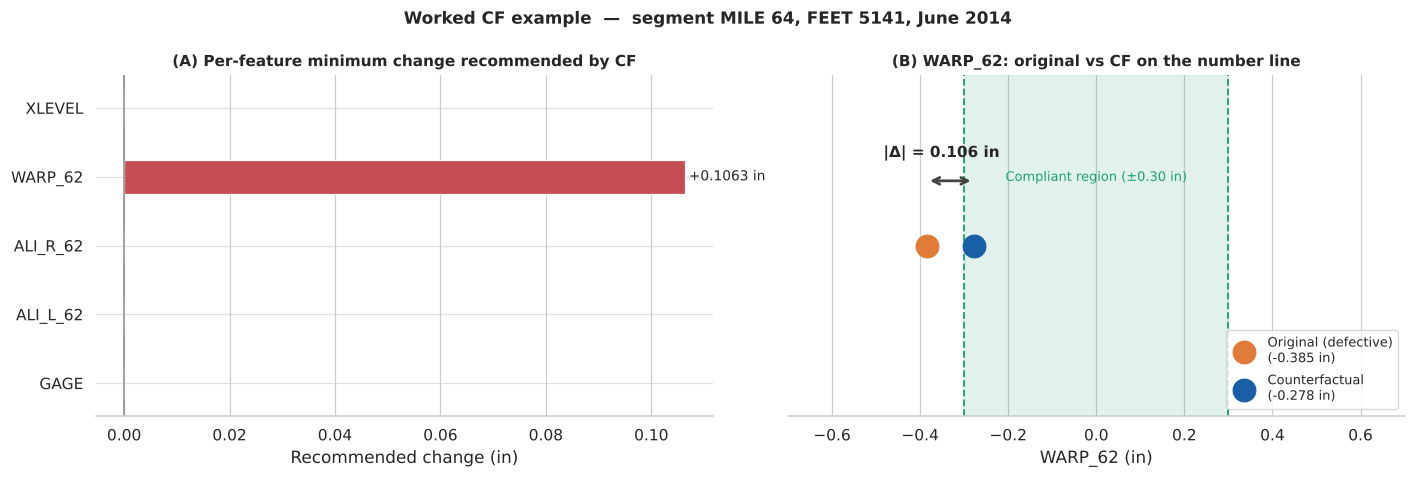

In [19]:
ex = cf_2014[(cf_2014['FEET'] == 5141) & (cf_2014['date'] == '2014-06-01')].iloc[0]
RESULTS['example_x0_warp'] = ex['x0_WARP_62']; RESULTS['example_cf_warp'] = ex['cf_WARP_62']
RESULTS['example_dwarp'] = abs(ex['d_WARP_62'])
print(f'WARP {ex["x0_WARP_62"]:.3f} to {ex["cf_WARP_62"]:.3f} in.,  |d| = {abs(ex["d_WARP_62"]):.3f} in.')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
ax = axes[0]
order = ['GAGE', 'ALI_L_62', 'ALI_R_62', 'WARP_62', 'XLEVEL']
deltas = [ex[f'd_{f}'] for f in order]
ax.barh(order, deltas, color=['#C44E52' if abs(d) > 1e-3 else '#BBBBBB' for d in deltas], height=0.5)
for i, d in enumerate(deltas):
    if abs(d) > 1e-3:
        ax.text(d + 0.0008, i, f'{d:+.4f} in', va='center', fontsize=9)
ax.axvline(0, color='#888888', linewidth=1)
ax.set_xlabel('Recommended change (in)')
ax.set_title('(A) Per-feature minimum change recommended by CF', fontsize=10)
ax.grid(axis='y', alpha=0.6); sns.despine(ax=ax, left=True)

ax = axes[1]
ax.axvspan(-0.30, 0.30, color='#1D9E75', alpha=0.13)
for v in (-0.30, 0.30):
    ax.axvline(v, color='#1D9E75', linestyle='--', linewidth=1.2)
ax.scatter([ex['x0_WARP_62']], [0], s=220, color='#E07B39', zorder=3,
           label=f'Original (defective)\n({ex["x0_WARP_62"]:.3f} in)')
ax.scatter([ex['cf_WARP_62']], [0], s=220, color='#185FA5', zorder=3,
           label=f'Counterfactual\n({ex["cf_WARP_62"]:.3f} in)')
ax.annotate('', xy=(ex['cf_WARP_62'], 0.19), xytext=(ex['x0_WARP_62'], 0.19),
            arrowprops=dict(arrowstyle='<->', color='#444441', lw=1.8))
ax.text((ex['x0_WARP_62'] + ex['cf_WARP_62']) / 2 - 0.02, 0.26, f'|Δ| = {abs(ex["d_WARP_62"]):.3f} in',
        ha='center', fontsize=10, fontweight='bold')
ax.text(0.0, 0.19, 'Compliant region (±0.30 in)', color='#1D9E75', fontsize=8.5, ha='center')
ax.set_xlim(-0.7, 0.7); ax.set_ylim(-0.5, 0.5); ax.set_yticks([])
ax.set_xlabel('WARP_62 (in)')
ax.set_title('(B) WARP_62: original vs CF on the number line', fontsize=10)
ax.legend(loc='lower right', fontsize=8.5); sns.despine(ax=ax, left=True)
fig.suptitle(f'Worked CF example  —  segment MILE {int(ex["MILE"])}, FEET {int(ex["FEET"])}, June 2014',
             fontsize=11, fontweight='bold')
fig.tight_layout()
save_fig(fig, 'cf_worked_example'); plt.show()

## 5. Severity validation against subsequent defect occurrence

Severity cannot be observed directly, so later defect occurrence at the same location is used as a proxy. For each observation, three outcomes are built from the next available inspections at that location.

| Outcome | Meaning |
|---|---|
| `persist_1` | defective at the next available inspection |
| `persist_3` | defective at least once within the next three inspections |
| `persist_6` | defective at least once within the next six inspections |

### 5.1 Build the outcomes for every record

In [20]:
panel = df.sort_values(['MILE', 'FEET', 'date']).copy()
grp = panel.groupby(['MILE', 'FEET'])['defect']
future = pd.concat({k: grp.shift(-k) for k in range(1, max(HORIZONS) + 1)}, axis=1)
has_next = future[1].notna()                       # no label when there is no later inspection
for h in HORIZONS:
    block = future[list(range(1, h + 1))]
    panel[f'persist_{h}'] = np.where(has_next, block.max(axis=1), np.nan)
    panel[f'count_{h}']   = np.where(has_next, block.sum(axis=1), np.nan)
df = df.join(panel[[f'persist_{h}' for h in HORIZONS] + [f'count_{h}' for h in HORIZONS]])
print(df[df['year'] == 2014][['persist_1', 'persist_3', 'persist_6']].notna().mean().round(3).to_dict())

{'persist_1': 1.0, 'persist_3': 1.0, 'persist_6': 1.0}


### 5.2 Baseline severity measures
* **Distance to limit**: largest exceedance of a project limit across the five features.
* **TQI (section)**: mean standard deviation of the five features over the whole section, per inspection.
* **TQI (200 ft)**: the same quantity within 61 m (200 ft) blocks, per inspection.

In [21]:
def distance_to_limit(values):
    ex = []
    for j, f in enumerate(FEATURES):
        lo, hi = PROJECT_LIMITS[f]
        ex.append(np.maximum.reduce([lo - values[:, j], values[:, j] - hi, np.zeros(len(values))]))
    return np.max(ex, axis=0)

df['dist_to_limit'] = distance_to_limit(df[FEATURES].values)
df['block200'] = df['FEET'] // 200
g_sec, g_200 = df.groupby(['date', 'MILE']), df.groupby(['date', 'block200'])
df['tqi_section'] = sum(g_sec[f].transform('std') for f in FEATURES) / len(FEATURES)
df['tqi_200ft']   = sum(g_200[f].transform('std') for f in FEATURES) / len(FEATURES)

# Evaluation table: one row per 2014 observation with a counterfactual
keep = ['dist_to_limit', 'tqi_section', 'tqi_200ft', 'warp_driven', 'xlevel_only'] + \
       [f'persist_{h}' for h in HORIZONS] + [f'count_{h}' for h in HORIZONS]
ev = cf_2014.join(df[keep], on='orig_idx')
ev['tier'] = pd.cut(ev['cf_warp_abs'], TIER_BINS, labels=TIER_NAMES)
print(f'evaluation cohort n = {len(ev)};  distinct section TQI values: {ev["tqi_section"].nunique()},'
      f'  distinct 200 ft TQI values: {ev["tqi_200ft"].nunique()}')

evaluation cohort n = 637;  distinct section TQI values: 8,  distinct 200 ft TQI values: 43


### 5.3 Table 5 and Figure 5. Severity tiers and persistence rates

,Count,Share_pct,next1_pct,next1_lo,next1_hi,next3_pct,next3_lo,next3_hi,next6_pct,next6_lo,next6_hi
Tier,,,,,,,,,,,
Marginal,260,40.8,29.2,23.8,35.2,42.3,36.2,48.6,46.5,40.4,52.8
Moderate,240,37.7,86.7,81.7,90.7,88.8,84.1,92.5,90.4,86.0,93.8
Severe,126,19.8,90.5,84.0,95.0,90.5,84.0,95.0,90.5,84.0,95.0
Critical,11,1.7,100.0,71.5,100.0,100.0,71.5,100.0,100.0,71.5,100.0


saved outputs/tables/table5_severity_tiers.csv


saved outputs/figures/defect_persistence.png and .pdf


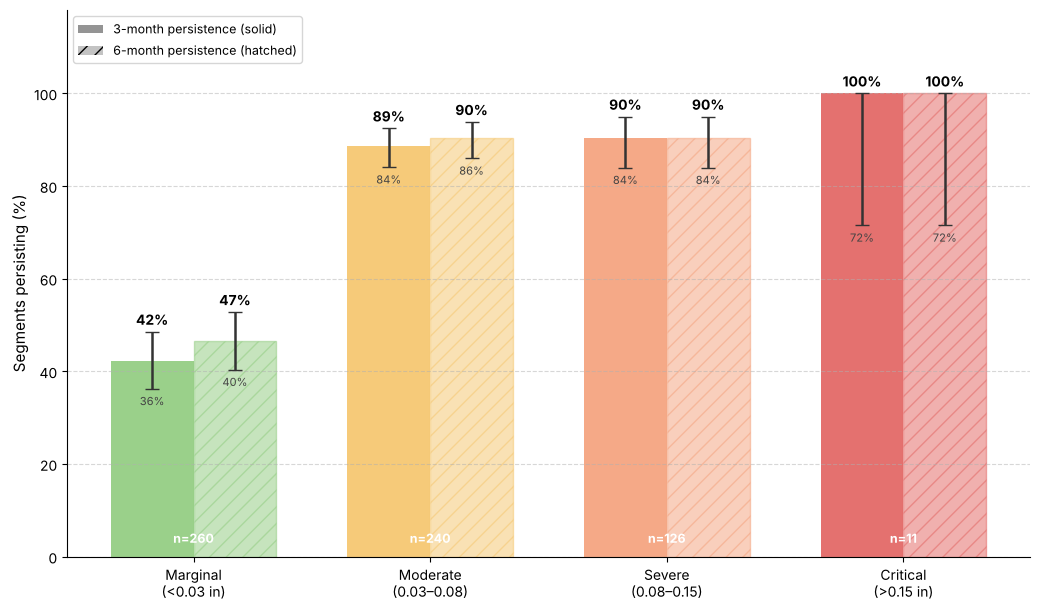

In [22]:
def clopper_pearson(k, n, alpha=0.05):
    lo = 0.0 if k == 0 else beta.ppf(alpha / 2, k, n - k + 1)
    hi = 1.0 if k == n else beta.ppf(1 - alpha / 2, k + 1, n - k)
    return lo, hi

rows = []
for t in TIER_NAMES:
    g = ev[ev['tier'] == t]; r = {'Tier': t, 'Count': len(g), 'Share_pct': 100 * len(g) / len(ev)}
    for h in HORIZONS:
        s = g[f'persist_{h}'].dropna(); k, n = int(s.sum()), len(s)
        lo, hi = clopper_pearson(k, n)
        r[f'next{h}_pct'] = 100 * k / n; r[f'next{h}_lo'] = 100 * lo; r[f'next{h}_hi'] = 100 * hi
    rows.append(r)
table5 = pd.DataFrame(rows).set_index('Tier')
display(table5.round(1))
save_table(table5, 'table5_severity_tiers')
for t in TIER_NAMES:
    RESULTS[f'tier_n_{t}'] = int(table5.loc[t, 'Count'])
    for h in HORIZONS:
        RESULTS[f'tier_next{h}_{t}'] = table5.loc[t, f'next{h}_pct']
RESULTS['critical_ci_low'] = table5.loc['Critical', 'next3_lo']

plt.rcdefaults()
fig, ax = plt.subplots(figsize=(10.5, 6.2))
colors = ['#8FCB7D', '#F5C56B', '#F4A07A', '#E2625F']
labels = ['Marginal\n(<0.03 in)', 'Moderate\n(0.03–0.08)', 'Severe\n(0.08–0.15)', 'Critical\n(>0.15 in)']
w, x = 0.35, np.arange(4)
for k, (h, hatch, a) in enumerate([(3, None, 0.9), (6, '//', 0.5)]):
    vals = table5[f'next{h}_pct'].values
    err = [vals - table5[f'next{h}_lo'].values, table5[f'next{h}_hi'].values - vals]
    pos = x - w / 2 + k * w
    ax.bar(pos, vals, w, color=colors, alpha=a, hatch=hatch, edgecolor=colors if hatch else None)
    ax.errorbar(pos, vals, yerr=err, fmt='none', ecolor='#333333', capsize=5, lw=1.8)
    for p, v, lo, hi in zip(pos, vals, table5[f'next{h}_lo'], table5[f'next{h}_hi']):
        ax.text(p, hi + 1.5, f'{v:.0f}%', ha='center', fontweight='bold', fontsize=10)
        ax.text(p, lo - 3.5, f'{lo:.0f}%', ha='center', fontsize=8, color='#444444')
for i, n in enumerate(table5['Count']):
    ax.text(i, 3, f'n={n}', ha='center', color='white', fontweight='bold', fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=10)
ax.set_ylabel('Segments persisting (%)', fontsize=11); ax.set_ylim(0, 118)
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.spines[['top', 'right']].set_visible(False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor='#888888', alpha=0.9, label='3-month persistence (solid)'),
                   Patch(facecolor='#888888', alpha=0.5, hatch='//', label='6-month persistence (hatched)')],
          loc='upper left', fontsize=9)
fig.tight_layout()
save_fig(fig, 'defect_persistence'); plt.show()
set_style()

### 5.4 Table 6. Spearman correlation with the number of defects in the next three inspections

In [23]:
predictors = [('|dWARP| (CF)', 'cf_warp_abs'), ('CF distance (MAD L1)', 'cf_dist'),
              ('Distance to limit', 'dist_to_limit'), ('TQI (200 ft)', 'tqi_200ft'),
              ('TQI (section)', 'tqi_section')]
rows = []
for label, col in predictors:
    s = ev[[col, 'count_3']].dropna()
    rho, p = spearmanr(s[col], s['count_3'])
    rows.append({'Predictor': label, 'rho': rho, 'p value': p,
                 'Significance': '***' if p < 0.001 else ('*' if p < 0.05 else 'n.s.')})
    RESULTS[f'rho_{col}'] = rho
table6 = pd.DataFrame(rows).set_index('Predictor')
display(table6.round({'rho': 3, 'p value': 3}))
save_table(table6, 'table6_spearman')
RESULTS['p_tqi_section'] = table6.loc['TQI (section)', 'p value']

,rho,p value,Significance
Predictor,,,
|dWARP| (CF),0.559,0.000,***
CF distance (MAD L1),0.314,0.000,***
Distance to limit,0.305,0.000,***
TQI (200 ft),0.497,0.000,***
TQI (section),0.014,0.722,n.s.


saved outputs/tables/table6_spearman.csv


### 5.5 Table 7. AUC of single predictors and joint models

Single predictors are scored directly on their values. Joint models are fitted by logistic regression on standardized predictors. The joint model is fitted with and without $|\Delta\mathrm{WARP}|$ to measure its contribution. These are within cohort values.

In [24]:
def auc_single(col):
    out = []
    for h in HORIZONS:
        s = ev[[col, f'persist_{h}']].dropna()
        out.append(roc_auc_score(s[f'persist_{h}'].astype(int), s[col]))
    return out

def auc_joint(cols):
    out = []
    for h in HORIZONS:
        s = ev[cols + [f'persist_{h}']].dropna()
        m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=20000, C=1e6))
        m.fit(s[cols], s[f'persist_{h}'].astype(int))
        out.append(roc_auc_score(s[f'persist_{h}'].astype(int), m.predict_proba(s[cols])[:, 1]))
    return out

AUC = {
    'C2': ('Counterfactual |dWARP|',                auc_single('cf_warp_abs')),
    'B2': ('TQI (200 ft)',                          auc_single('tqi_200ft')),
    'C':  ('CF distance',                           auc_single('cf_dist')),
    'A':  ('Distance to limit',                     auc_single('dist_to_limit')),
    'B':  ('TQI (section)',                         auc_single('tqi_section')),
    'D2': ('Distance + TQI (200 ft)',               auc_joint(['dist_to_limit', 'tqi_200ft'])),
    'E3': ('Distance + TQI (200 ft) + CF |dWARP|',  auc_joint(['dist_to_limit', 'tqi_200ft', 'cf_warp_abs'])),
}
table7 = pd.DataFrame({k: [v[0]] + v[1] for k, v in AUC.items()},
                      index=['Features', 'Next 1', 'Next 3', 'Next 6']).T
display(table7.style.format({c: '{:.3f}' for c in ['Next 1', 'Next 3', 'Next 6']}))
save_table(table7, 'table7_auc')
for k, v in AUC.items():
    for h, a in zip(HORIZONS, v[1]):
        RESULTS[f'auc_{k}_{h}'] = a

,Features,Next 1,Next 3,Next 6
C2,Counterfactual |dWARP|,0.864,0.841,0.838
B2,TQI (200 ft),0.789,0.835,0.861
C,CF distance,0.716,0.650,0.626
A,Distance to limit,0.705,0.637,0.608
B,TQI (section),0.515,0.502,0.511
D2,Distance + TQI (200 ft),0.835,0.844,0.863
E3,Distance + TQI (200 ft) + CF |dWARP|,0.879,0.873,0.886


saved outputs/tables/table7_auc.csv


### 5.6 Figure 4. Severity predictor comparison

saved outputs/figures/validation_A.png and .pdf


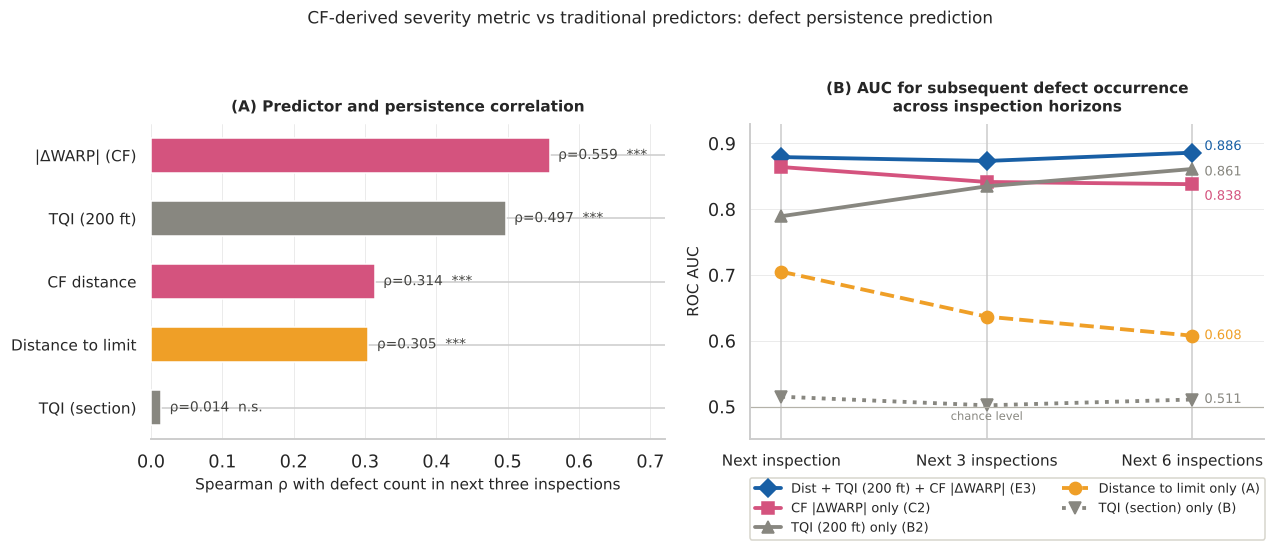

In [25]:
C_CF, C_DIST, C_COMBO, C_TQI = '#D4537E', '#EF9F27', '#185FA5', '#888780'
sns.set_theme(style='whitegrid', font_scale=1.05)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ax = axes[0]
order = [('|ΔWARP| (CF)', 'cf_warp_abs', C_CF), ('TQI (200 ft)', 'tqi_200ft', C_TQI),
         ('CF distance', 'cf_dist', C_CF), ('Distance to limit', 'dist_to_limit', C_DIST),
         ('TQI (section)', 'tqi_section', C_TQI)]
y = np.arange(len(order))
vals = [RESULTS[f'rho_{c}'] for _, c, _ in order]
ax.barh(y, vals[::-1], color=[c for _, _, c in order][::-1], edgecolor='white', height=0.55)
ax.set_yticks(y); ax.set_yticklabels([l for l, _, _ in order][::-1], fontsize=10)
ax.set_xlim(0, 0.72)
ax.set_xlabel('Spearman ρ with defect count in next three inspections', fontsize=10)
ax.set_title('(A) Predictor and persistence correlation', fontsize=10, pad=8, fontweight='bold')
pvals = dict(zip(table6.index, table6['p value']))
plab = {'cf_warp_abs': '|dWARP| (CF)', 'tqi_200ft': 'TQI (200 ft)', 'cf_dist': 'CF distance (MAD L1)',
        'dist_to_limit': 'Distance to limit', 'tqi_section': 'TQI (section)'}
for i, (_, c, _) in enumerate(order[::-1]):
    p = pvals[plab[c]]; star = '***' if p < 0.001 else ('*' if p < 0.05 else 'n.s.')
    ax.text(RESULTS[f'rho_{c}'] + 0.012, i, f'ρ={RESULTS[f"rho_{c}"]:.3f}  {star}',
            va='center', fontsize=9, color='#444441')
ax.grid(axis='x', linewidth=0.5, alpha=0.5); sns.despine(ax=ax, left=True)

ax = axes[1]; x = np.arange(3)
series = [('E3', 'Dist + TQI (200 ft) + CF |ΔWARP| (E3)', C_COMBO, 'D', '-', 4),
          ('C2', 'CF |ΔWARP| only (C2)', C_CF, 's', '-', -8),
          ('B2', 'TQI (200 ft) only (B2)', C_TQI, '^', '-', -2),
          ('A',  'Distance to limit only (A)', C_DIST, 'o', '--', 0),
          ('B',  'TQI (section) only (B)', C_TQI, 'v', ':', 0)]
for k, lab, col, mk, ls, off in series:
    ax.plot(x, AUC[k][1], marker=mk, linewidth=2.5, markersize=8, color=col, linestyle=ls, label=lab)
    ax.annotate(f'{AUC[k][1][-1]:.3f}', (2, AUC[k][1][-1]), textcoords='offset points',
                xytext=(8, off), fontsize=8.5, color=col, va='center')
ax.set_xticks(x); ax.set_xticklabels(['Next inspection', 'Next 3 inspections', 'Next 6 inspections'], fontsize=10)
ax.set_xlim(-0.15, 2.35); ax.set_ylim(0.45, 0.93)
ax.axhline(0.5, color='#B4B2A9', linewidth=0.8)
ax.text(1.0, 0.493, 'chance level', fontsize=7.5, color='#888780', va='top', ha='center')
ax.set_ylabel('ROC AUC', fontsize=10)
ax.set_title('(B) AUC for subsequent defect occurrence\nacross inspection horizons',
             fontsize=10, pad=8, fontweight='bold')
ax.legend(fontsize=8.5, framealpha=0.9, edgecolor='#D3D1C7', loc='upper center',
          bbox_to_anchor=(0.5, -0.10), ncol=2)
ax.grid(axis='y', linewidth=0.5, alpha=0.5); sns.despine(ax=ax)
plt.suptitle('CF-derived severity metric vs traditional predictors: defect persistence prediction',
             fontsize=11, y=1.02)
plt.tight_layout()
save_fig(fig, 'validation_A'); plt.show()
set_style()

### 5.7 Figure 6 and Section 5.4. Counterfactual severity against threshold exceedance

saved outputs/figures/cf_vs_physical.png and .pdf


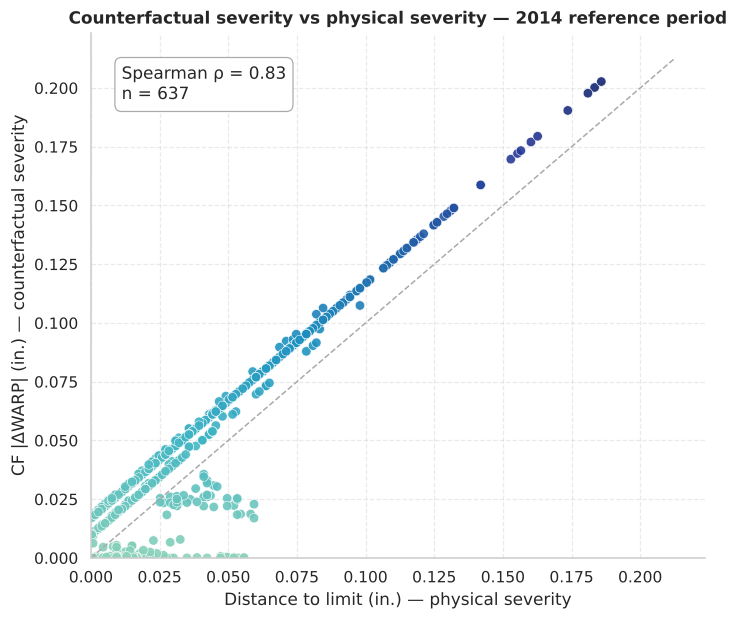

Spearman rho between |dWARP| and distance to limit: 0.832


In [26]:
rho_cf_dtl = spearmanr(ev['cf_warp_abs'], ev['dist_to_limit'])[0]
RESULTS['rho_cf_vs_dtl'] = rho_cf_dtl

fig, ax = plt.subplots(figsize=(7.2, 6.2))
sc = ax.scatter(ev['dist_to_limit'], ev['cf_warp_abs'], c=ev['cf_warp_abs'], cmap='YlGnBu',
                vmin=-0.12, vmax=0.22, s=38, edgecolor='white', linewidth=0.4, alpha=0.9)
lim = max(ev['dist_to_limit'].max(), ev['cf_warp_abs'].max()) * 1.05
ax.plot([0, lim], [0, lim], linestyle='--', color='#AAAAAA', linewidth=1)
ax.set_xlim(0, lim * 1.05); ax.set_ylim(0, lim * 1.05)
ax.set_xlabel('Distance to limit (in.) — physical severity')
ax.set_ylabel('CF |ΔWARP| (in.) — counterfactual severity')
ax.set_title('Counterfactual severity vs physical severity — 2014 reference period')
ax.text(0.05, 0.94, f'Spearman ρ = {rho_cf_dtl:.2f}\nn = {len(ev)}', transform=ax.transAxes, va='top',
        bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor='#AAAAAA'))
ax.grid(alpha=0.4, linestyle='--')
save_fig(fig, 'cf_vs_physical'); plt.show()
print(f'Spearman rho between |dWARP| and distance to limit: {rho_cf_dtl:.3f}')

**Direction of the correction.** For WARP driven defects the perturbation should move WARP toward zero. For XLEVEL only defects it should bring XLEVEL inside its project limit.

In [27]:
w = ev[ev['warp_driven'] == True]
x = ev[ev['xlevel_only'] == True]
scaled = np.abs(w[[f'd_{f}' for f in FEATURES]].values) / MAD
RESULTS['n_warp_driven_cf'] = len(w)
RESULTS['n_xlevel_only_cf'] = len(x)
RESULTS['warp_toward_zero_pct'] = 100 * (w['cf_WARP_62'].abs() < w['x0_WARP_62'].abs()).mean()
RESULTS['warp_share_of_distance_pct'] = 100 * (scaled[:, WARP] / scaled.sum(axis=1)).mean()
RESULTS['xlevel_inside_limit_pct'] = 100 * (x['cf_XLEVEL'].abs() <= 0.80).mean()
print(f'WARP driven defects with a counterfactual : {len(w)}')
print(f'  WARP moves toward zero                  : {RESULTS["warp_toward_zero_pct"]:.1f}%')
print(f'  WARP share of the MAD scaled distance   : {RESULTS["warp_share_of_distance_pct"]:.1f}%')
print(f'XLEVEL only defects with a counterfactual : {len(x)}')
print(f'  XLEVEL ends inside the project limit    : {RESULTS["xlevel_inside_limit_pct"]:.1f}%')

WARP driven defects with a counterfactual : 511
  WARP moves toward zero                  : 100.0%
  WARP share of the MAD scaled distance   : 99.1%
XLEVEL only defects with a counterfactual : 126
  XLEVEL ends inside the project limit    : 100.0%


## 6. Temporal transfer of the 2014 reference perturbations

The 2014 counterfactuals are stored as a reference library. Their perturbations are applied to defective observations from later periods **without** running the search again. The classifier stays fixed.

* **P1, mean perturbation.** One mean perturbation vector is applied to every observation.
* **P2, nearest neighbor.** Each observation receives the perturbation of its nearest 2014 reference observation (MAD scaled Euclidean distance).

In both protocols the WARP component is signed so that it points toward zero, and the result is clipped to the FRA limits. A flip is counted when the classifier prediction changes from defective to not defective.

In [28]:
REF_X = cf_2014[[f'x0_{f}' for f in FEATURES]].values
REF_D = cf_2014[[f'd_{f}' for f in FEATURES]].values
MEAN_D = REF_D.mean(axis=0)

def apply_transfer(model, target, ref_x=REF_X, ref_d=REF_D, protocol='P2'):
    """Apply reference perturbations to the defective rows of `target`.
    Returns a frame with the predicted class before, the flip flag and the neighbor distance."""
    tgt = target[target['defect'] == 1]
    X0 = tgt[FEATURES].values.astype(float)
    dist = np.sqrt(((X0[:, None, :] / MAD - ref_x[None, :, :] / MAD) ** 2).sum(axis=2))
    nn = dist.argmin(axis=1)
    deltas = ref_d[nn].copy() if protocol == 'P2' else np.tile(ref_d.mean(axis=0), (len(X0), 1))
    positive = X0[:, WARP] > 0
    deltas[positive, WARP]  = -np.abs(deltas[positive, WARP])      # point WARP toward zero
    deltas[~positive, WARP] = +np.abs(deltas[~positive, WARP])
    X1 = np.clip(X0 + deltas, FRA_LO, FRA_HI)
    before, after = model.predict(X0), model.predict(X1)
    return pd.DataFrame({'pred_defective': before == 1, 'flipped': (before == 1) & (after == 0),
                         'nn_dist': dist.min(axis=1), 'p_after': model.predict_proba(X1)[:, 1]},
                        index=tgt.index)

def flip_rate(detail):
    n = int(detail['pred_defective'].sum()); k = int(detail['flipped'].sum())
    return k, n, 100 * k / max(1, n)

### 6.1 Table 9. Transfer flip rates

In [29]:
rows, DETAIL = [], {}
for label, year in [('2014 (reference)', 2014), ('2015', 2015), ('2016', 2016)]:
    target = df[df['year'] == year]
    d1, d2 = apply_transfer(model, target, protocol='P1'), apply_transfer(model, target, protocol='P2')
    DETAIL[year] = d2
    k1, n1, r1 = flip_rate(d1); k2, n2, r2 = flip_rate(d2)
    rows.append({'Period': label, 'N eval': n2, 'P1 flipped': k1, 'P1 rate (%)': r1,
                 'P2 flipped': k2, 'P2 rate (%)': r2})
    RESULTS[f'p1_flipped_{year}'] = k1; RESULTS[f'p1_rate_{year}'] = r1
    RESULTS[f'p2_flipped_{year}'] = k2; RESULTS[f'p2_rate_{year}'] = r2; RESULTS[f'n_eval_{year}'] = n2
    RESULTS[f'n_labeled_def_{year}'] = int((target['defect'] == 1).sum())
table9 = pd.DataFrame(rows).set_index('Period')
display(table9.round(1))
save_table(table9, 'table9_transfer')

,N eval,P1 flipped,P1 rate (%),P2 flipped,P2 rate (%)
Period,,,,,
2014 (reference),649,203,31.3,637,98.2
2015,1672,366,21.9,476,28.5
2016,2092,105,5.0,144,6.9


saved outputs/tables/table9_transfer.csv


### 6.2 Figure 7. Classifier discrimination against transfer flip rate

saved outputs/figures/model_vs_cf.png and .pdf


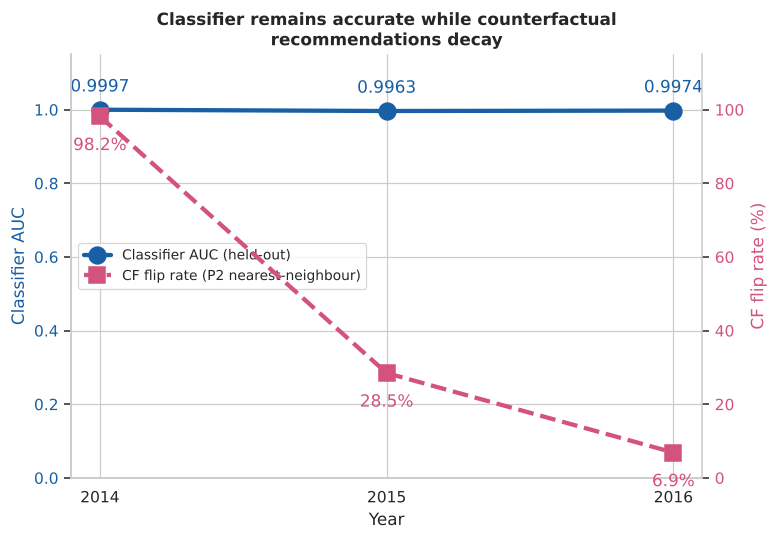

In [30]:
years = [2014, 2015, 2016]
aucs  = [RESULTS['clf_auc_train'], RESULTS['clf_auc_2015'], RESULTS['clf_auc_2016']]
flips = [RESULTS[f'p2_rate_{y}'] for y in years]

fig, ax1 = plt.subplots(figsize=(7.4, 5))
ax1.plot(years, aucs, marker='o', markersize=11, linewidth=2.8, color='#185FA5', label='Classifier AUC (held-out)')
for xx, v in zip(years, aucs):
    ax1.annotate(f'{v:.4f}', (xx, v), textcoords='offset points', xytext=(0, 12), ha='center', color='#185FA5')
ax1.set_ylim(0, 1.15); ax1.set_ylabel('Classifier AUC', color='#185FA5'); ax1.tick_params(axis='y', labelcolor='#185FA5')
ax1.set_xticks(years); ax1.set_xlabel('Year')
ax2 = ax1.twinx()
ax2.plot(years, flips, marker='s', markersize=11, linewidth=2.8, linestyle='--', color='#D4537E',
         label='CF flip rate (P2 nearest-neighbour)')
for xx, v in zip(years, flips):
    ax2.annotate(f'{v:.1f}%', (xx, v), textcoords='offset points', xytext=(0, -22), ha='center', color='#D4537E')
ax2.set_ylim(0, 115); ax2.set_ylabel('CF flip rate (%)', color='#D4537E'); ax2.tick_params(axis='y', labelcolor='#D4537E')
ax2.grid(False); ax2.spines['right'].set_visible(True)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='center left', fontsize=9)
ax1.set_title('Classifier remains accurate while counterfactual\nrecommendations decay')
save_fig(fig, 'model_vs_cf'); plt.show()

### 6.3 Monthly flip rates and the season matched comparison (Section 5.5)

In [31]:
rows = []
for date, g in df[df['year'] >= 2014].groupby('date'):
    k, n, r = flip_rate(apply_transfer(model, g, protocol='P2'))
    rows.append({'date': date, 'flipped': k, 'n_eval': n, 'flip_rate': r,
                 'warp_tail': 100 * (g['WARP_62'].abs() > 0.30).mean(),
                 'defect_rate': 100 * g['defect'].mean()})
monthly = pd.DataFrame(rows).set_index('date')
display(monthly.round(1))
save_table(monthly, 'monthly_flip_rates')

def window_rate(mask):
    return flip_rate(apply_transfer(model, df[mask], protocol='P2'))
jan_apr = df['month'].isin([1, 2, 3, 4])
k15, n15, r15 = window_rate((df['year'] == 2015) & jan_apr)
k16, n16, r16 = window_rate((df['year'] == 2016) & jan_apr)
RESULTS['p2_jan_apr_2015'] = r15; RESULTS['p2_jan_apr_2016'] = r16
RESULTS['p2_nov_2015'] = monthly.loc['2015-11-01', 'flip_rate']
RESULTS['p2_dec_2015'] = monthly.loc['2015-12-01', 'flip_rate']
print(f'January to April 2015: {r15:.1f}%  ({k15} of {n15})')
print(f'January to April 2016: {r16:.1f}%  ({k16} of {n16})')
print(f'November 2015: {RESULTS["p2_nov_2015"]:.1f}%   December 2015: {RESULTS["p2_dec_2015"]:.1f}%')

,flipped,n_eval,flip_rate,warp_tail,defect_rate
date,,,,,
2014-01-01,52,52,100.0,1.0,1.0
2014-03-01,76,76,100.0,1.4,1.4
2014-04-01,76,76,100.0,1.4,1.4
2014-06-01,196,208,94.2,1.3,3.9
2014-07-01,79,79,100.0,1.5,1.5
2014-10-01,53,53,100.0,1.0,1.0
2014-11-01,52,52,100.0,1.0,1.0
2014-12-01,53,53,100.0,1.0,1.0
2015-01-01,24,60,40.0,1.1,1.1


saved outputs/tables/monthly_flip_rates.csv
January to April 2015: 41.9%  (195 of 465)
January to April 2016: 6.9%  (144 of 2092)
November 2015: 18.1%   December 2015: 12.5%


### 6.4 Mechanisms of counterfactual failure (Section 5.6)
Three quantities are examined: the size of the WARP exceedance, the defect composition, and the distance to the reference set.

In [32]:
print('Failure mode 1: correction magnitude')
for y in (2014, 2015, 2016):
    wd = df[(df['year'] == y) & df['warp_driven']]
    exc = (wd['WARP_62'].abs() - 0.30).mean()
    RESULTS[f'warp_exceedance_in_{y}'] = exc
    print(f'  {y}: mean WARP exceedance {exc:.3f} in. = {25.4*exc:.2f} mm')
ref_mean = abs(MEAN_D[WARP])
need_2016 = (df[(df['year'] == 2016) & df['warp_driven']]['WARP_62'].abs() - RESULTS['warp_flip_point']).mean()
RESULTS['ref_mean_dwarp_in'] = ref_mean; RESULTS['need_2016_in'] = need_2016
RESULTS['need_ratio'] = need_2016 / ref_mean
print(f'  reference mean WARP perturbation: {ref_mean:.3f} in. = {25.4*ref_mean:.2f} mm')
print(f'  2016 mean change needed to reach the boundary: {need_2016:.3f} in. = {25.4*need_2016:.2f} mm '
      f'({RESULTS["need_ratio"]:.1f} times)')

print('\nFailure mode 2: defect composition')
print(f'  XLEVEL only: {RESULTS["xlevel_only_pct_2014"]:.1f}% (2014) to {RESULTS["xlevel_only_pct_2016"]:.1f}% (2016);'
      f'  any XLEVEL in 2016: {RESULTS["any_xlevel_pct_2016"]:.1f}%')

print('\nFailure mode 3: distance to the reference set (MAD scaled)')
for y in (2015, 2016):
    d = DETAIL[y]; tp = d[d['pred_defective']]
    RESULTS[f'n_nonflipped_{y}'] = int((~tp['flipped']).sum())
    RESULTS[f'nn_nonflip_{y}'] = d[~d['flipped']]['nn_dist'].mean()
    RESULTS[f'nn_flip_{y}']    = d[d['flipped']]['nn_dist'].mean()
    print(f'  {y}: not flipped {RESULTS[f"nn_nonflip_{y}"]:.2f}, flipped {RESULTS[f"nn_flip_{y}"]:.2f}'
          f'   (true positives not flipped: {RESULTS[f"n_nonflipped_{y}"]:,};'
          f' restricted to them: {tp[~tp["flipped"]]["nn_dist"].mean():.2f})')

Failure mode 1: correction magnitude
  2014: mean WARP exceedance 0.044 in. = 1.12 mm
  2015: mean WARP exceedance 0.060 in. = 1.52 mm
  2016: mean WARP exceedance 0.127 in. = 3.22 mm
  reference mean WARP perturbation: 0.037 in. = 0.95 mm
  2016 mean change needed to reach the boundary: 0.144 in. = 3.65 mm (3.8 times)

Failure mode 2: defect composition
  XLEVEL only: 21.3% (2014) to 37.2% (2016);  any XLEVEL in 2016: 44.4%

Failure mode 3: distance to the reference set (MAD scaled)
  2015: not flipped 3.00, flipped 1.70   (true positives not flipped: 1,196; restricted to them: 2.90)
  2016: not flipped 4.66, flipped 2.56   (true positives not flipped: 1,948; restricted to them: 4.53)


### 6.5 Figure 8. Example of a stale counterfactual

WARP -0.334 to -0.297 in.,  predicted defect probability after = 0.98


saved outputs/figures/cf_stale_example.png and .pdf


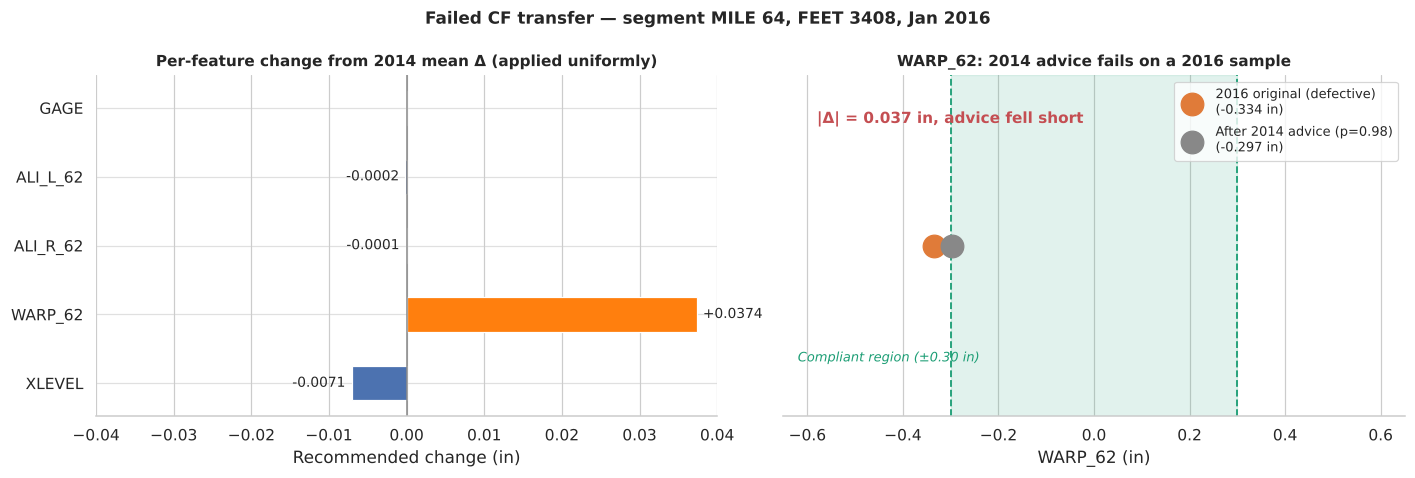

In [33]:
stale = df[(df['FEET'] == 3408) & (df['date'] == '2016-01-01')].iloc[0]
x0 = stale[FEATURES].values.astype(float)
delta = MEAN_D.copy(); delta[WARP] = abs(MEAN_D[WARP]) if x0[WARP] < 0 else -abs(MEAN_D[WARP])
x1 = np.clip(x0 + delta, FRA_LO, FRA_HI)
p1 = model.predict_proba(x1.reshape(1, -1))[0, 1]
RESULTS['stale_x0_warp'] = x0[WARP]; RESULTS['stale_after_warp'] = x1[WARP]; RESULTS['stale_p_after'] = p1
print(f'WARP {x0[WARP]:.3f} to {x1[WARP]:.3f} in.,  predicted defect probability after = {p1:.2f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
ax = axes[0]
order = ['XLEVEL', 'WARP_62', 'ALI_R_62', 'ALI_L_62', 'GAGE']
dv = [delta[FEATURES.index(f)] for f in order]
ax.barh(order, dv, color=['#4C72B0' if d < 0 else '#FF7F0E' for d in dv], height=0.5)
for i, d in enumerate(dv):
    if abs(d) > 5e-5:
        ax.text(d + (0.0008 if d > 0 else -0.0008), i, f'{d:+.4f}', va='center',
                ha='left' if d > 0 else 'right', fontsize=9)
ax.axvline(0, color='#888888', linewidth=1); ax.set_xlim(-0.04, 0.04)
ax.set_xlabel('Recommended change (in)')
ax.set_title('Per-feature change from 2014 mean Δ (applied uniformly)', fontsize=10)
ax.grid(axis='y', alpha=0.6); sns.despine(ax=ax, left=True)

ax = axes[1]
ax.axvspan(-0.30, 0.30, color='#1D9E75', alpha=0.13)
for v in (-0.30, 0.30):
    ax.axvline(v, color='#1D9E75', linestyle='--', linewidth=1.2)
ax.scatter([x0[WARP]], [0], s=220, color='#E07B39', zorder=3, label=f'2016 original (defective)\n({x0[WARP]:.3f} in)')
ax.scatter([x1[WARP]], [0], s=220, color='#888888', zorder=3, label=f'After 2014 advice (p={p1:.2f})\n({x1[WARP]:.3f} in)')
ax.text(-0.58, 0.36, f'|Δ| = {abs(delta[WARP]):.3f} in, advice fell short', color='#C44E52', fontweight='bold', fontsize=10)
ax.text(-0.62, -0.34, 'Compliant region (±0.30 in)', color='#1D9E75', fontsize=8.5, style='italic')
ax.set_xlim(-0.65, 0.65); ax.set_ylim(-0.5, 0.5); ax.set_yticks([])
ax.set_xlabel('WARP_62 (in)'); ax.set_title('WARP_62: 2014 advice fails on a 2016 sample', fontsize=10)
ax.legend(loc='upper right', fontsize=8.5); sns.despine(ax=ax, left=True)
fig.suptitle(f'Failed CF transfer — segment MILE {int(stale["MILE"])}, FEET {int(stale["FEET"])}, Jan 2016',
             fontsize=11, fontweight='bold')
fig.tight_layout()
save_fig(fig, 'cf_stale_example'); plt.show()

### 6.6 Figure 9. Monthly flip rate against WARP tail exceedance (Section 5.8)

Pearson r, flip rate against WARP tail probability: -0.789
Pearson r, flip rate against defect rate          : -0.722


saved outputs/figures/monthly_flip.png and .pdf


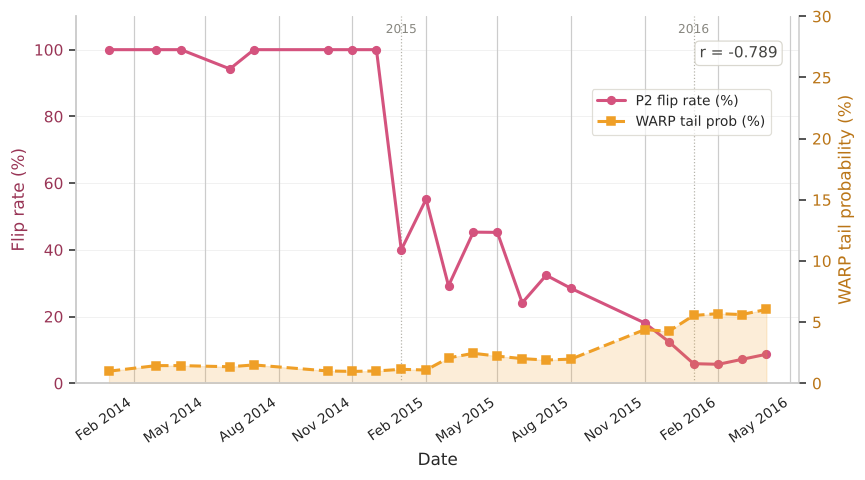

In [34]:
r_tail = pearsonr(monthly['flip_rate'], monthly['warp_tail'])[0]
r_rate = pearsonr(monthly['flip_rate'], monthly['defect_rate'])[0]
RESULTS['r_flip_vs_tail'] = r_tail; RESULTS['r_flip_vs_defect_rate'] = r_rate
print(f'Pearson r, flip rate against WARP tail probability: {r_tail:.3f}')
print(f'Pearson r, flip rate against defect rate          : {r_rate:.3f}')

fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.plot(monthly.index, monthly['flip_rate'], color='#D4537E', linewidth=2, marker='o', markersize=5,
         label='P2 flip rate (%)', zorder=3)
ax1.set_ylabel('Flip rate (%)', fontsize=11, color='#993556'); ax1.tick_params(axis='y', labelcolor='#993556')
ax1.set_ylim(0, 110)
ax2 = ax1.twinx()
ax2.fill_between(monthly.index, monthly['warp_tail'], alpha=0.18, color='#EF9F27', zorder=1)
ax2.plot(monthly.index, monthly['warp_tail'], color='#EF9F27', linewidth=2, marker='s', markersize=5,
         linestyle='--', label='WARP tail prob (%)', zorder=2)
ax2.set_ylabel('WARP tail probability (%)', fontsize=11, color='#BA7517'); ax2.tick_params(axis='y', labelcolor='#BA7517')
ax2.set_ylim(0, 30); ax2.grid(False)
for yr in (2015, 2016):
    ax1.axvline(pd.Timestamp(f'{yr}-01-01'), color='#B4B2A9', linewidth=0.8, linestyle=':', zorder=0)
    ax1.text(pd.Timestamp(f'{yr}-01-01'), 105, str(yr), ha='center', fontsize=8, color='#888780')
ax1.text(0.97, 0.92, f'r = {r_tail:.3f}', transform=ax1.transAxes, ha='right', va='top', fontsize=10,
         color='#444441', bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#D3D1C7', alpha=0.85))
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
plt.setp(ax1.get_xticklabels(), rotation=35, ha='right', fontsize=9)
ax1.set_xlabel('Date', fontsize=11); ax1.grid(axis='y', linewidth=0.5, alpha=0.35)
sns.despine(ax=ax1, right=False)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, fontsize=9, framealpha=0.7, edgecolor='#D3D1C7', loc='upper right',
           bbox_to_anchor=(0.97, 0.82))
plt.tight_layout()
save_fig(fig, 'monthly_flip'); plt.show()

## 7. Recalibration: new counterfactuals for later periods

Here the search of Section 4 is run again for WARP driven defective observations in each evaluation year, instead of reusing the 2014 perturbations.

* **2015** uses the unchanged 2013 to 2014 classifier.
* **2016** uses a classifier with the same settings trained on 2013 to 2015.

The success rate is the share of observations for which the search returns a counterfactual.

In [35]:
model_recal, spw_recal = train_classifier((2013, 2014, 2015))
print(f'recalibrated classifier trained on 2013 to 2015, scale_pos_weight = {spw_recal:.2f}')
print(f'  ROC AUC on 2016: {roc_auc_score(df[df["year"]==2016]["defect"], model_recal.predict_proba(df[df["year"]==2016][FEATURES].values)[:,1]):.4f}')

RECAL = {}
for year, mdl, training in [(2015, model, '2013 to 2014'), (2016, model_recal, '2013 to 2015')]:
    cohort = df[(df['year'] == year) & (df['defect'] == 1) & df['warp_driven']]
    cfs = generate_cfs(mdl, cohort, f'new{year}')
    RECAL[year] = {'training': training, 'n': len(cohort), 'success': len(cfs),
                   'rate': 100 * len(cfs) / len(cohort)}
    RESULTS[f'n_warp_driven_{year}'] = len(cohort)
    RESULTS[f'recal_rate_{year}'] = RECAL[year]['rate']

recalibrated classifier trained on 2013 to 2015, scale_pos_weight = 39.59
  ROC AUC on 2016: 0.9992
[new2015] loaded 1218 counterfactuals from cache
[new2016] loaded 1015 counterfactuals from cache


### 7.1 Tables 10 and 11

In [36]:
table10 = pd.DataFrame({y: {'Classifier training data': v['training'], 'N evaluated': v['n'],
                            'Counterfactuals found': v['success'], 'Success (%)': round(v['rate'], 1)}
                        for y, v in RECAL.items()}).T
table10.index.name = 'Year'
display(table10); save_table(table10, 'table10_new_generation')

table11 = pd.DataFrame({y: {'N defects (evaluated)': RESULTS[f'n_eval_{y}'],
                            'N WARP driven': RECAL[y]['n'],
                            'Stale (%)': round(RESULTS[f'p2_rate_{y}'], 1),
                            'Recalibrated (%)': round(RECAL[y]['rate'], 1)} for y in RECAL}).T
table11.index.name = 'Evaluation period'
display(table11); save_table(table11, 'table11_recalibration')

,Classifier training data,N evaluated,Counterfactuals found,Success (%)
Year,,,,
2015,2013 to 2014,1237,1218,98.5
2016,2013 to 2015,1206,1015,84.2


saved outputs/tables/table10_new_generation.csv


,N defects (evaluated),N WARP driven,Stale (%),Recalibrated (%)
Evaluation period,,,,
2015,1672.0,1237.0,28.5,98.5
2016,2092.0,1206.0,6.9,84.2


saved outputs/tables/table11_recalibration.csv


### 7.2 Figure 10. Recalibration recovery

saved outputs/figures/recal_recovery.png and .pdf


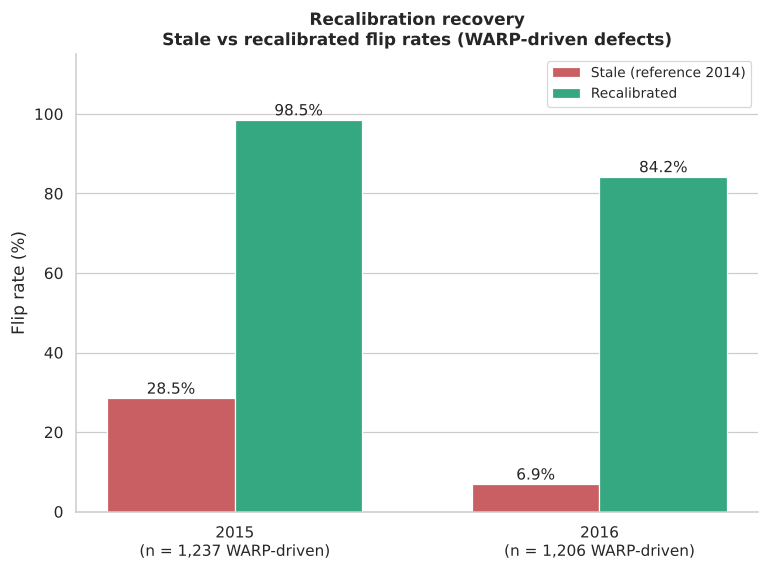

In [37]:
fig, ax = plt.subplots(figsize=(8, 5.4))
x = np.arange(2); w = 0.35
stale = [RESULTS['p2_rate_2015'], RESULTS['p2_rate_2016']]
recal = [RECAL[2015]['rate'], RECAL[2016]['rate']]
b1 = ax.bar(x - w / 2, stale, w, color='#C95F62', label='Stale (reference 2014)')
b2 = ax.bar(x + w / 2, recal, w, color='#35A882', label='Recalibrated')
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1.2, f'{b.get_height():.1f}%', ha='center', fontsize=10)
ax.set_xticks(x)
ax.set_xticklabels([f'{y}\n(n = {RECAL[y]["n"]:,} WARP-driven)' for y in (2015, 2016)], fontsize=10)
ax.set_ylabel('Flip rate (%)'); ax.set_ylim(0, 115)
ax.set_title('Recalibration recovery\nStale vs recalibrated flip rates (WARP-driven defects)')
ax.legend(loc='upper right', fontsize=9); ax.grid(axis='x', visible=False)
save_fig(fig, 'recal_recovery'); plt.show()

## 8. Sensitivity to the proximity weight (Appendix)

The 2014 reference counterfactuals are regenerated for seven values of $\lambda$. For each value the severity validation and the temporal transfer are repeated. $\rho$ is the Spearman rank correlation of $|\Delta\mathrm{WARP}|$ with the $\lambda = 0.5$ solution.

In [38]:
if RUN_LAMBDA_SWEEP:
    base_abs = cf_2014.set_index('orig_idx')['cf_warp_abs']
    rows = []
    for lam in LAMBDA_GRID:
        cfs = cf_2014 if lam == LAMBDA else generate_cfs(model, cohort_2014, f'ref2014_lam{lam}', lam=lam)
        e = cfs.join(df[[f'persist_{h}' for h in HORIZONS]], on='orig_idx')
        this = cfs.set_index('orig_idx')['cf_warp_abs']
        common = base_abs.index.intersection(this.index)
        row = {'lambda': lam, 'Counterfactuals': len(cfs),
               'Mean |dWARP| (in.)': cfs['cf_warp_abs'].mean(),
               'rho': spearmanr(base_abs[common], this[common])[0]}
        for h in HORIZONS:
            s = e[['cf_warp_abs', f'persist_{h}']].dropna()
            row[f'AUC next {h}'] = roc_auc_score(s[f'persist_{h}'].astype(int), s['cf_warp_abs'])
        rx = cfs[[f'x0_{f}' for f in FEATURES]].values; rd = cfs[[f'd_{f}' for f in FEATURES]].values
        for y in (2015, 2016):
            row[f'P2 {y} (%)'] = flip_rate(apply_transfer(model, df[df['year'] == y], rx, rd, 'P2'))[2]
        rows.append(row)
    table_lambda = pd.DataFrame(rows).set_index('lambda')
    display(table_lambda.round({'Mean |dWARP| (in.)': 4, 'rho': 3, 'AUC next 1': 3, 'AUC next 3': 3,
                                'AUC next 6': 3, 'P2 2015 (%)': 1, 'P2 2016 (%)': 1}))
    save_table(table_lambda, 'appendix_lambda_sensitivity')
    for lam, r in table_lambda.iterrows():
        RESULTS[f'lam{lam}_n'] = int(r['Counterfactuals']); RESULTS[f'lam{lam}_mean'] = r['Mean |dWARP| (in.)']
        RESULTS[f'lam{lam}_rho'] = r['rho']; RESULTS[f'lam{lam}_auc1'] = r['AUC next 1']
        RESULTS[f'lam{lam}_auc3'] = r['AUC next 3']; RESULTS[f'lam{lam}_auc6'] = r['AUC next 6']
        RESULTS[f'lam{lam}_p2_2015'] = r['P2 2015 (%)']; RESULTS[f'lam{lam}_p2_2016'] = r['P2 2016 (%)']
else:
    print('Skipped. Set RUN_LAMBDA_SWEEP = True in Section 0 to run it.')

[ref2014_lam0.05] loaded 638 counterfactuals from cache


[ref2014_lam0.1] loaded 639 counterfactuals from cache


[ref2014_lam0.25] loaded 638 counterfactuals from cache


[ref2014_lam1.0] loaded 640 counterfactuals from cache
[ref2014_lam2.0] loaded 642 counterfactuals from cache


[ref2014_lam5.0] loaded 644 counterfactuals from cache


,Counterfactuals,Mean |dWARP| (in.),rho,AUC next 1,AUC next 3,AUC next 6,P2 2015 (%),P2 2016 (%)
lambda,,,,,,,,
0.05,638,0.0503,0.978,0.878,0.862,0.863,30.4,7.6
0.10,639,0.0499,0.978,0.879,0.864,0.865,30.6,7.3
0.25,638,0.0497,0.983,0.869,0.848,0.845,29.4,7.6
0.50,637,0.0494,1.000,0.864,0.841,0.838,28.5,6.9
1.00,640,0.0487,0.979,0.870,0.850,0.848,26.6,5.9
2.00,642,0.0488,0.981,0.866,0.844,0.841,26.7,6.0
5.00,644,0.0487,0.984,0.866,0.843,0.840,26.7,5.9


saved outputs/tables/appendix_lambda_sensitivity.csv


## 9. Check against the values reported in the paper

Every value below is compared with the number printed in the manuscript, at the precision the manuscript uses. `OK` means the notebook reproduces it.

In [39]:
# (key in RESULTS, value in the paper, decimals used in the paper, where it appears)
PAPER = [
 ('n_records', 147550, 0, 'Sec. 3.1'), ('n_locations', 5279, 0, 'Sec. 3.1'),
 ('pct_locations_all_years', 99.8, 1, 'Sec. 3.1'), ('overall_defect_rate_pct', 3.55, 2, 'Sec. 3.1'),
 ('N_2013', 31620, 0, 'Table 1'), ('N_2014', 42152, 0, 'Table 1'), ('N_2015', 52696, 0, 'Table 1'), ('N_2016', 21082, 0, 'Table 1'),
 ('defects_2013', 775, 0, 'Table 1'), ('defects_2014', 649, 0, 'Table 1'), ('defects_2015', 1692, 0, 'Table 1'), ('defects_2016', 2129, 0, 'Table 1'),
 ('rate_2013', 2.45, 2, 'Table 1'), ('rate_2014', 1.54, 2, 'Table 1'), ('rate_2015', 3.21, 2, 'Table 1'), ('rate_2016', 10.10, 2, 'Table 1'),
 ('warp_sigma_2013', 0.0983, 4, 'Table 1'), ('warp_sigma_2014', 0.0959, 4, 'Table 1'), ('warp_sigma_2015', 0.1047, 4, 'Table 1'), ('warp_sigma_2016', 0.1406, 4, 'Table 1'),
 ('warp_tail_2013', 0.0127, 4, 'Table 1'), ('warp_tail_2014', 0.0121, 4, 'Table 1'), ('warp_tail_2015', 0.0235, 4, 'Table 1'), ('warp_tail_2016', 0.0572, 4, 'Table 1'),
 ('warp_sd_ref', 0.097, 3, 'Sec. 4.1'), ('warp_sd_2016', 0.141, 3, 'Sec. 4.1'), ('gage_sd_2015', 0.094, 3, 'Sec. 4.1'),
 ('tail_ref_pct', 1.2, 1, 'Sec. 4.1'), ('tail_2016_pct', 5.7, 1, 'Sec. 4.1'), ('tail_fold', 4.6, 1, 'Sec. 4.1'),
 ('trigger_WARP_62', 3354, 0, 'Fig. 1'), ('trigger_XLEVEL', 1642, 0, 'Fig. 1'), ('trigger_ALI_R_62', 385, 0, 'Fig. 1'), ('trigger_ALI_L_62', 276, 0, 'Fig. 1'), ('trigger_GAGE', 12, 0, 'Fig. 1'),
 ('warp_driven_pct_2014', 78.7, 1, 'Sec. 4.2'), ('xlevel_only_pct_2014', 21.3, 1, 'Sec. 4.2'), ('xlevel_only_pct_2016', 37.2, 1, 'Sec. 4.2'), ('any_xlevel_pct_2016', 44.4, 1, 'Sec. 5.6'),
 ('ks_xlevel_2013_2014', 0.083, 3, 'Sec. 5.5'), ('ks_xlevel_2014_2015', 0.161, 3, 'Sec. 5.5'), ('ks_xlevel_2015_2016', 0.430, 3, 'Sec. 5.5'),
 ('mi_WARP_62', 0.0550, 4, 'Table 3'), ('mi_XLEVEL', 0.0216, 4, 'Table 3'), ('mi_ALI_R_62', 0.0143, 4, 'Table 3'), ('mi_ALI_L_62', 0.0139, 4, 'Table 3'), ('mi_GAGE', 0.0091, 4, 'Table 3'),
 ('scale_pos_weight', 50.81, 2, 'Sec. 3.3'),
 ('clf_precision_train', 0.796, 3, 'Table 8'), ('clf_recall_train', 1.000, 3, 'Table 8'), ('clf_f1_train', 0.886, 3, 'Table 8'), ('clf_auc_train', 0.9997, 4, 'Table 8'),
 ('clf_precision_2015', 0.848, 3, 'Table 8'), ('clf_recall_2015', 0.988, 3, 'Table 8'), ('clf_f1_2015', 0.913, 3, 'Table 8'), ('clf_auc_2015', 0.9963, 4, 'Table 8'),
 ('clf_precision_2016', 0.917, 3, 'Table 8'), ('clf_recall_2016', 0.983, 3, 'Table 8'), ('clf_f1_2016', 0.949, 3, 'Table 8'), ('clf_auc_2016', 0.9974, 4, 'Table 8'),
 ('n_def_2014', 649, 0, 'Table 4'), ('n_cf_2014', 637, 0, 'Table 4'), ('cf_success_pct', 98.2, 1, 'Table 4'),
 ('mean_cf_dist', 1.125, 3, 'Table 4'), ('mean_abs_dWARP', 0.0494, 4, 'Table 4'), ('mean_abs_dXLEVEL', 0.0073, 4, 'Table 4'), ('warp_flip_point', 0.283, 3, 'Table 4'),
 ('example_x0_warp', -0.385, 3, 'Fig. 3'), ('example_cf_warp', -0.278, 3, 'Fig. 3'), ('example_dwarp', 0.106, 3, 'Fig. 3'),
 ('tier_n_Marginal', 260, 0, 'Table 5'), ('tier_n_Moderate', 240, 0, 'Table 5'), ('tier_n_Severe', 126, 0, 'Table 5'), ('tier_n_Critical', 11, 0, 'Table 5'),
 ('tier_next1_Marginal', 29, 0, 'Table 5'), ('tier_next1_Moderate', 87, 0, 'Table 5'), ('tier_next1_Severe', 90, 0, 'Table 5'), ('tier_next1_Critical', 100, 0, 'Table 5'),
 ('tier_next3_Marginal', 42, 0, 'Sec. 5.3'), ('tier_next3_Critical', 100, 0, 'Sec. 5.3'),
 ('rho_cf_warp_abs', 0.559, 3, 'Table 6'), ('rho_cf_dist', 0.314, 3, 'Table 6'), ('rho_dist_to_limit', 0.305, 3, 'Table 6'), ('rho_tqi_200ft', 0.497, 3, 'Table 6'), ('rho_tqi_section', 0.014, 3, 'Table 6'), ('p_tqi_section', 0.722, 3, 'Table 6'),
 ('auc_C2_1', 0.864, 3, 'Table 7'), ('auc_C2_3', 0.841, 3, 'Table 7'), ('auc_C2_6', 0.838, 3, 'Table 7'),
 ('auc_B2_1', 0.789, 3, 'Table 7'), ('auc_B2_3', 0.835, 3, 'Table 7'), ('auc_B2_6', 0.861, 3, 'Table 7'),
 ('auc_C_1', 0.716, 3, 'Table 7'), ('auc_C_3', 0.650, 3, 'Table 7'), ('auc_C_6', 0.626, 3, 'Table 7'),
 ('auc_A_1', 0.705, 3, 'Table 7'), ('auc_A_3', 0.637, 3, 'Table 7'), ('auc_A_6', 0.608, 3, 'Table 7'),
 ('auc_B_1', 0.515, 3, 'Table 7'), ('auc_B_3', 0.502, 3, 'Table 7'), ('auc_B_6', 0.511, 3, 'Table 7'),
 ('auc_D2_1', 0.835, 3, 'Table 7'), ('auc_D2_3', 0.844, 3, 'Table 7'), ('auc_D2_6', 0.863, 3, 'Table 7'),
 ('auc_E3_1', 0.879, 3, 'Table 7'), ('auc_E3_3', 0.873, 3, 'Table 7'), ('auc_E3_6', 0.886, 3, 'Table 7'),
 ('rho_cf_vs_dtl', 0.83, 2, 'Fig. 6'),
 ('n_warp_driven_cf', 511, 0, 'Sec. 5.4'), ('n_xlevel_only_cf', 126, 0, 'Sec. 5.4'), ('warp_toward_zero_pct', 100, 0, 'Sec. 5.4'), ('warp_share_of_distance_pct', 99.1, 1, 'Sec. 5.4'), ('xlevel_inside_limit_pct', 100, 0, 'Sec. 5.4'),
 ('n_labeled_def_2015', 1692, 0, 'Sec. 5.5'), ('n_eval_2014', 649, 0, 'Table 9'), ('n_eval_2015', 1672, 0, 'Table 9'), ('n_eval_2016', 2092, 0, 'Table 9'),
 ('p1_flipped_2014', 203, 0, 'Table 9'), ('p1_rate_2014', 31.3, 1, 'Table 9'), ('p2_flipped_2014', 637, 0, 'Table 9'), ('p2_rate_2014', 98.2, 1, 'Table 9'),
 ('p1_flipped_2015', 366, 0, 'Table 9'), ('p1_rate_2015', 21.9, 1, 'Table 9'), ('p2_flipped_2015', 476, 0, 'Table 9'), ('p2_rate_2015', 28.5, 1, 'Table 9'),
 ('p1_flipped_2016', 105, 0, 'Table 9'), ('p1_rate_2016', 5.0, 1, 'Table 9'), ('p2_flipped_2016', 144, 0, 'Table 9'), ('p2_rate_2016', 6.9, 1, 'Table 9'),
 ('p2_jan_apr_2015', 41.9, 1, 'Sec. 5.5'), ('p2_jan_apr_2016', 6.9, 1, 'Sec. 5.5'), ('p2_nov_2015', 18.1, 1, 'Sec. 5.5'), ('p2_dec_2015', 12.5, 1, 'Sec. 5.5'),
 ('warp_exceedance_in_2014', 0.044, 3, 'Sec. 5.6'), ('warp_exceedance_in_2015', 0.060, 3, 'Sec. 5.6'), ('warp_exceedance_in_2016', 0.127, 3, 'Sec. 5.6'),
 ('ref_mean_dwarp_in', 0.037, 3, 'Sec. 5.6'), ('need_2016_in', 0.144, 3, 'Sec. 5.6'), ('need_ratio', 3.9, 1, 'Sec. 5.6'),
 ('n_nonflipped_2015', 1196, 0, 'Sec. 5.6'), ('n_nonflipped_2016', 1948, 0, 'Sec. 5.6'),
 ('nn_nonflip_2015', 3.00, 2, 'Sec. 5.6'), ('nn_flip_2015', 1.70, 2, 'Sec. 5.6'), ('nn_nonflip_2016', 4.66, 2, 'Sec. 5.6'), ('nn_flip_2016', 2.56, 2, 'Sec. 5.6'),
 ('stale_x0_warp', -0.334, 3, 'Sec. 5.7 and Fig. 8'), ('stale_after_warp', -0.297, 3, 'Fig. 8'), ('stale_p_after', 0.98, 2, 'Fig. 8'),
 ('r_flip_vs_tail', -0.789, 3, 'Sec. 5.8'), ('r_flip_vs_defect_rate', -0.722, 3, 'Sec. 5.8'),
 ('n_warp_driven_2015', 1237, 0, 'Table 10'), ('n_warp_driven_2016', 1206, 0, 'Table 10'),
 ('recal_rate_2015', 98.5, 1, 'Table 10'), ('recal_rate_2016', 84.2, 1, 'Table 10'),
]
LAMBDA_PAPER = {0.05: (638, 0.0503, 0.978, 0.878, 0.862, 0.863, 30.4, 7.6),
                0.1:  (639, 0.0499, 0.978, 0.879, 0.864, 0.865, 30.6, 7.3),
                0.25: (638, 0.0497, 0.983, 0.869, 0.848, 0.845, 29.4, 7.6),
                0.5:  (637, 0.0494, 1.000, 0.864, 0.841, 0.838, 28.5, 6.9),
                1.0:  (640, 0.0487, 0.979, 0.870, 0.850, 0.848, 26.6, 5.9),
                2.0:  (642, 0.0488, 0.981, 0.866, 0.844, 0.841, 26.7, 6.0),
                5.0:  (644, 0.0487, 0.984, 0.866, 0.843, 0.840, 26.7, 5.9)}
if RUN_LAMBDA_SWEEP:
    for lam, vals in LAMBDA_PAPER.items():
        for key, v, dec in zip(['n', 'mean', 'rho', 'auc1', 'auc3', 'auc6', 'p2_2015', 'p2_2016'], vals,
                               [0, 4, 3, 3, 3, 3, 1, 1]):
            PAPER.append((f'lam{lam}_{key}', v, dec, 'Appendix'))

rows = []
for key, paper, dec, where in PAPER:
    got = RESULTS.get(key, np.nan)
    ok = (not pd.isna(got)) and abs(round(float(got), dec) - paper) <= 0.5 * 10 ** (-dec) + 1e-12
    rows.append({'Where': where, 'Quantity': key, 'Paper': paper, 'Notebook': round(float(got), dec + 1),
                 'Status': 'OK' if ok else 'DIFFERS'})
check = pd.DataFrame(rows)
save_table(check.set_index('Quantity'), 'check_against_paper')
n_ok = int((check['Status'] == 'OK').sum())
print(f'{n_ok} of {len(check)} reported values reproduced.')
diff = check[check['Status'] != 'OK']
if len(diff):
    print('\nValues that differ from the paper:')
    display(diff)
else:
    print('All reported values are reproduced.')

saved outputs/tables/check_against_paper.csv
209 of 210 reported values reproduced.

Values that differ from the paper:


,Where,Quantity,Paper,Notebook,Status
138,Sec. 5.6,need_ratio,3.9,3.84,DIFFERS


### Notes on the comparison

* **Required change in 2016 (Sec. 5.6).** The paper states that the 2016 change is "approximately 3.9 times" the reference mean perturbation. That figure is the ratio of the two rounded values in millimetres (3.67 / 0.94). The unrounded ratio computed here is 3.8.
* **Nearest neighbor distances (Sec. 5.6).** The means 3.00, 1.70, 4.66 and 2.56 are taken over all labeled defective observations. The counts 1,196 and 1,948 refer to the observations that the classifier predicts as defective and that do not flip. Section 6.4 prints both versions.
* **Stale example (Sec. 5.7 and Fig. 8).** The figure uses the mean perturbation protocol, which moves WARP to the value printed above with the probability printed above. The sentence in Section 5.7 of the manuscript quotes a different end value and probability and should be checked against the figure.
* **Recalibration (Table 10).** The 2015 success rate is 1,218 of 1,237, which rounds to the reported 98.5%.

### Full list of checked values

In [40]:
pd.set_option('display.max_rows', 300)
display(check)

,Where,Quantity,Paper,Notebook,Status
0,Sec. 3.1,n_records,147550.0000,147550.00000,OK
1,Sec. 3.1,n_locations,5279.0000,5279.00000,OK
2,Sec. 3.1,pct_locations_all_years,99.8000,99.81000,OK
3,Sec. 3.1,overall_defect_rate_pct,3.5500,3.55500,OK
4,Table 1,N_2013,31620.0000,31620.00000,OK
5,Table 1,N_2014,42152.0000,42152.00000,OK
6,Table 1,N_2015,52696.0000,52696.00000,OK
7,Table 1,N_2016,21082.0000,21082.00000,OK
8,Table 1,defects_2013,775.0000,775.00000,OK
9,Table 1,defects_2014,649.0000,649.00000,OK


## Output files

| Folder | Content |
|---|---|
| `outputs/figures` | The ten paper figures as PNG and PDF |
| `outputs/tables` | Every table as CSV, plus `check_against_paper.csv` |
| `outputs/cache` | Saved counterfactuals, reused on the next run |

To copy the outputs to Google Drive from Colab, run the cell below.

In [41]:
# Optional: copy the outputs folder to Google Drive (Colab only)
# import shutil; shutil.copytree('outputs', '/content/drive/MyDrive/counterfactual_outputs', dirs_exist_ok=True)